#  Agriculture Market Price Records
### Data Analysis Project Using Python

**Prepared by:** Nusaira  
**Course:** Data Analyst Course  


### 1. Introduction
This project focuses on analyzing agricultural commodity prices across different states and markets in India using Python. The aim is to understand price variations and identify useful insights from agricultural market data.

### 2. Dataset Source
The dataset, *Current Daily Price of Various Commodities from Various Markets (Mandi)*, contains agricultural commodity prices collected from different markets in India for two reporting dates.

1.	Dataset: Government of India, Current Daily Price of Various Commodities from Various Markets (Mandi). Available at: https://www.data.gov.in/resource/current-daily-price-various-commodities-various-markets-mandi

**Source:** The original Mandi dataset used for this project.

The dataset contains agricultural market price records collected for two reporting dates and combined for analysis.

### 3. Dataset Information
- **Number of Rows:** 28268
- **Number of Columns:** 10
- **Data Types:** Categorical, date, and numerical data
- **Main Information:** State, District, Market, Commodity, Variety, Grade, Arrival Date, Minimum Price, Maximum Price, and Modal Price.

### 4. Tools and Libraries
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly

### 5. Project Objectives
- Analyze agricultural commodity prices.
- Compare average modal prices across states.
- Identify commodities with higher average modal prices.
- Examine price distributions and potential outliers.
- Visualize findings using charts and graphs.

### 5. Project Workflow
Data loading → Data exploration → Data cleaning → Exploratory Data Analysis (EDA) → Data visualization → Conclusion.

In [ ]:

from google.colab import files

uploaded = files.upload()

Saving Agricultural_Market_Price_Records.csv to Agricultural_Market_Price_Records.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    'Agricultural_Market_Price_Records.csv'
)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (28268, 10)


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
0,Odisha,Mayurbhanja,Baripada APMC,Bitter gourd,Bitter Gourd,Medium,13-10-2026,5000.0,6000.0,5500.0
1,Odisha,Mayurbhanja,Baripada APMC,Brinjal,Brinjal,Medium,13-10-2026,4500.0,6000.0,5000.0
2,Keralam,Kozhikode(Calicut),Mukkom Market,Beetroot,Beetroot,FAQ,13-10-2026,3400.0,3900.0,3600.0
3,Keralam,Kozhikode(Calicut),Mukkom Market,Drumstick,Drumstick,FAQ,13-10-2026,4800.0,5200.0,5000.0
4,Keralam,Kozhikode(Calicut),Mukkom Market,Onion,Onion,FAQ,13-10-2026,5000.0,5400.0,5200.0


In [ ]:

# Step 1: Check Data Types

# Display the data type of every column
df.dtypes


,0
State,object
District,object
Market,object
Commodity,object
Variety,object
Grade,object
Arrival_Date,object
Min_x0020_Price,float64
Max_x0020_Price,float64
Modal_x0020_Price,float64


Here my date coloumn is in object type ,so i want to change it to datetime

In [ ]:
df['Arrival_Date'] = pd.to_datetime(df['Arrival_Date'], dayfirst=True)

In [ ]:
df.dtypes

,0
State,object
District,object
Market,object
Commodity,object
Variety,object
Grade,object
Arrival_Date,datetime64[ns]
Min_x0020_Price,float64
Max_x0020_Price,float64
Modal_x0020_Price,float64


Converts the Arrival_Date column into a proper date format, with the day appearing first, followed by the month and year

In [ ]:
display(df.head())

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
0,Odisha,Mayurbhanja,Baripada APMC,Bitter gourd,Bitter Gourd,Medium,2026-10-13,5000.0,6000.0,5500.0
1,Odisha,Mayurbhanja,Baripada APMC,Brinjal,Brinjal,Medium,2026-10-13,4500.0,6000.0,5000.0
2,Keralam,Kozhikode(Calicut),Mukkom Market,Beetroot,Beetroot,FAQ,2026-10-13,3400.0,3900.0,3600.0
3,Keralam,Kozhikode(Calicut),Mukkom Market,Drumstick,Drumstick,FAQ,2026-10-13,4800.0,5200.0,5000.0
4,Keralam,Kozhikode(Calicut),Mukkom Market,Onion,Onion,FAQ,2026-10-13,5000.0,5400.0,5200.0


### Data Cleaning

The dataset was checked for missing values, duplicate records, extra spaces, inconsistent text entries, and data types. No missing values or duplicate records were found. Extra spaces were identified in the District and Market columns and cleaned. Selected inconsistent text entries were standardized to improve data quality and prepare the dataset for further analysis.

In [ ]:

df.isnull().sum()


,0
State,0
District,0
Market,0
Commodity,0
Variety,0
Grade,0
Arrival_Date,0
Min_x0020_Price,0
Max_x0020_Price,0
Modal_x0020_Price,0


All 10 columns have zero missing values, which means there are no missing values in the dataset.

In [ ]:

df.isnull().sum().sum()


np.int64(0)

there are zero missing values in the dataset.

In [ ]:

df.duplicated().sum()


np.int64(0)

there are no duplicate rows in the dataset.

#Step 4: Fix Inconsistent Values

In [ ]:

df['Commodity'].unique()


array(['Bitter gourd', 'Brinjal', 'Beetroot', 'Drumstick', 'Onion',
       'Tomato', 'Cowpea(Veg)', 'Snakeguard', 'Pumpkin',
       'Elephant Yam(Suran)/Amorphophallus', 'Paddy(Common)',
       'Little gourd(Kundru)', 'Cabbage', 'Carrot', 'Bottle gourd',
       'Cucumbar(Kheera)', 'Cauliflower', 'Papaya(Raw)', 'Potato',
       'Banana', 'Ginger(Green)', 'Bhindi(Ladies Finger)',
       'Jowar(Sorghum)', 'Sesamum(Sesame,Gingelly,Til)', 'Beans',
       'Banana - Green', 'Lemon', 'Mango(Raw-Ripe)', 'Tapioca', 'Cotton',
       'Groundnut', 'Cummin Seed(Jeera)', 'Wheat', 'Papaya',
       'Mousambi(Sweet Lime)', 'Colacasia', 'Spinach', 'Capsicum',
       'Apple', 'Methi(Leaves)', 'Yam(Ratalu)', 'Sweet Potato',
       'Coriander(Leaves)', 'Bajra(Pearl Millet/Cumbu)',
       'Ridgeguard(Tori)', 'Pineapple', 'Water Melon',
       'Pointed gourd(Parval)', 'Tender Coconut', 'Peas Wet',
       'Barley(Jau)', 'Garlic', 'Mustard', 'Corriander seed', 'Orange',
       'Pomegranate', 'Cluster beans', 'G

Displays all unique commodity names present in the Commodity column.

In [ ]:

text_columns = ['State', 'District', 'Market',
                'Commodity', 'Variety', 'Grade']

for col in text_columns:
    df[col] = df[col].str.strip()


Removes extra spaces from the beginning and end of text values in the selected columns.

In [ ]:

# Check unique values in text columns

text_columns = ['State', 'District', 'Market',
                'Commodity', 'Variety', 'Grade']

for col in text_columns:
    print(f"\nUnique values in {col}:")
    print(sorted(df[col].dropna().unique()))



Unique values in State:
['Andaman and Nicobar', 'Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chattisgarh', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Keralam', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'NCT of Delhi', 'Nagaland', 'Odisha', 'Pondicherry', 'Punjab', 'Rajasthan', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Unique values in District:
['Adilabad', 'Agar Malwa', 'Agra', 'Ahilyanagar', 'Ahmedabad', 'Ajmer', 'Akola', 'Alappuzha', 'Aligarh', 'Alipurduar', 'Alirajpur', 'Alluri Sitharama Raju', 'Alwar', 'Amarawati', 'Ambala', 'Ambedkarnagar', 'Amethi', 'Amreli', 'Amritsar', 'Amroha', 'Anakapally', 'Anand', 'Ananthapuramu', 'Angul', 'Annamayya', 'Anupur', 'Ariyalur', 'Arwal', 'Ashoknagar', 'Auraiya', 'Aurangabad', 'Ayodhya', 'Azamgarh', 'Badaun', 'Badwani', 'Bagalkot', 'Baghpat', 'Bahraich', 'Balaghat', 'Balasore', 'Ballia', 'Balrampur', 'Banaskanth', 'Banda', 'Banka', 'Bankura', 'Bap

In [ ]:

#  Count unique values in each text column

for col in text_columns:
    print(f"{col}: {df[col].nunique()} unique values")


State: 28 unique values
District: 514 unique values
Market: 1801 unique values
Commodity: 256 unique values
Variety: 495 unique values
Grade: 14 unique values


In [ ]:

#  Check capitalization inconsistencies

for col in text_columns:
    print(f"\n{col}:")
    print(df[col].dropna().apply(str.lower).unique())




State:
['odisha' 'keralam' 'madhya pradesh' 'telangana' 'bihar' 'gujarat'
 'andhra pradesh' 'punjab' 'haryana' 'rajasthan' 'jammu and kashmir'
 'tamil nadu' 'karnataka' 'maharashtra' 'west bengal' 'uttar pradesh'
 'chattisgarh' 'pondicherry' 'tripura' 'himachal pradesh' 'uttarakhand'
 'assam' 'nct of delhi' 'nagaland' 'manipur' 'chandigarh' 'meghalaya'
 'andaman and nicobar']

District:
['mayurbhanja' 'kozhikode(calicut)' 'wayanad' 'mandla' 'hyderabad'
 'rayagada' 'koraput' 'mandsaur' 'begusarai' 'pathanamthitta'
 'ranga reddy' 'rajkot' 'ernakulam' 'surendranagar' 'eluru' 'sabarkantha'
 'fazilka' 'tirupathi' 'kurukshetra' 'panipat' 'rewari' 'sonipat' 'hissar'
 'narsinghpur' 'gurdaspur' 'hoshiarpur' 'jalandhar' 'kollam' 'ganganagar'
 'kota' 'jaipur' 'baran' 'hanumangarh' 'ntr' 'jalore' 'ludhiana' 'dewas'
 'kottayam' 'bolangir' 'baramulla' 'kupwara' 'rajgarh' 'alappuzha' 'jammu'
 'thiruvananthapuram' 'mehsana' 'thiruchirappalli' 'pathankot' 'patiala'
 'ropar (rupnagar)' 'sangrur' 'palak

In [ ]:

#  Display original unique values

text_columns = ['State', 'District', 'Market',
                'Commodity', 'Variety', 'Grade']

for col in text_columns:
    print(f"\n--- {col} ---")
    print(sorted(df[col].dropna().unique()))



--- State ---
['Andaman and Nicobar', 'Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chattisgarh', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Keralam', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'NCT of Delhi', 'Nagaland', 'Odisha', 'Pondicherry', 'Punjab', 'Rajasthan', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

--- District ---
['Adilabad', 'Agar Malwa', 'Agra', 'Ahilyanagar', 'Ahmedabad', 'Ajmer', 'Akola', 'Alappuzha', 'Aligarh', 'Alipurduar', 'Alirajpur', 'Alluri Sitharama Raju', 'Alwar', 'Amarawati', 'Ambala', 'Ambedkarnagar', 'Amethi', 'Amreli', 'Amritsar', 'Amroha', 'Anakapally', 'Anand', 'Ananthapuramu', 'Angul', 'Annamayya', 'Anupur', 'Ariyalur', 'Arwal', 'Ashoknagar', 'Auraiya', 'Aurangabad', 'Ayodhya', 'Azamgarh', 'Badaun', 'Badwani', 'Bagalkot', 'Baghpat', 'Bahraich', 'Balaghat', 'Balasore', 'Ballia', 'Balrampur', 'Banaskanth', 'Banda', 'Banka', 'Bankura', 'Bapatla', 'Barabanki', 

In [ ]:

#  Find capitalization inconsistencies

text_columns = ['State', 'District', 'Market',
                'Commodity', 'Variety', 'Grade']

for col in text_columns:
    temp = df[col].dropna().astype(str)

    grouped = temp.groupby(temp.str.strip().str.lower()).unique()

    inconsistent = grouped[grouped.apply(
        lambda values: len(values) > 1
    )]

    if len(inconsistent) > 0:
        print(f"\nPossible inconsistencies in {col}:")
        for values in inconsistent:
            print(values)
    else:
        print(f"\n{col}: No capitalization inconsistencies found.")



State: No capitalization inconsistencies found.

District: No capitalization inconsistencies found.

Market: No capitalization inconsistencies found.

Commodity: No capitalization inconsistencies found.

Variety: No capitalization inconsistencies found.

Grade: No capitalization inconsistencies found.


In [ ]:

#  Check possible formatting inconsistencies

import re
import pandas as pd

text_columns = ['State', 'District', 'Market',
                'Commodity', 'Variety', 'Grade']

for col in text_columns:
    temp = df[col].dropna().astype(str)

    normalized = temp.apply(
        lambda x: re.sub(r'[\s\W_]+', '', x).lower()
    )

    groups = pd.DataFrame({
        'original': temp,
        'normalized': normalized
    }).groupby('normalized')['original'].unique()

    issues = groups[groups.apply(lambda x: len(x) > 1)]

    print(f"\n--- {col} ---")
    if len(issues) == 0:
        print("No obvious formatting differences found.")
    else:
        for values in issues:
            print(values)



--- State ---
No obvious formatting differences found.

--- District ---
No obvious formatting differences found.

--- Market ---
['AJattihalli(Uzhavar Sandhai )' 'A.Jattihalli(Uzhavar Sandhai )']
['Ashta APMC' 'Ashta  APMC']

--- Commodity ---
No obvious formatting differences found.

--- Variety ---
['F.A.Q.' 'F.A.Q']
['Ground Nut Seed' 'Groundnut seed']
['I.R.-64' 'I.R. 64']
['(Whole)' 'Whole']

--- Grade ---
No obvious formatting differences found.


In [ ]:

# Inspect possible inconsistencies in Market

market_values = [
    'AJattihalli(Uzhavar Sandhai )',
    'A.Jattihalli(Uzhavar Sandhai )',
    'Ashta APMC',
    'Ashta  APMC'
]

for value in market_values:
    print(f"\nSearching for: {value!r}")

    display(
        df.loc[df['Market'] == value,
               ['State', 'District', 'Market']]
        .head(10)
    )



Searching for: 'AJattihalli(Uzhavar Sandhai )'


,State,District,Market
722,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
723,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
724,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
725,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
726,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
727,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
3722,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
3723,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
3724,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )
3725,Tamil Nadu,Dharmapuri,AJattihalli(Uzhavar Sandhai )



Searching for: 'A.Jattihalli(Uzhavar Sandhai )'


,State,District,Market
16191,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
16192,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
16193,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
16194,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
16195,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
16196,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
18713,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
18714,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
18715,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )
18716,Tamil Nadu,Dharmapuri,A.Jattihalli(Uzhavar Sandhai )



Searching for: 'Ashta APMC'


,State,District,Market
2783,Madhya Pradesh,Sehore,Ashta APMC
8976,Madhya Pradesh,Sehore,Ashta APMC
15323,Madhya Pradesh,Sehore,Ashta APMC
15324,Madhya Pradesh,Sehore,Ashta APMC
15325,Madhya Pradesh,Sehore,Ashta APMC
17951,Madhya Pradesh,Sehore,Ashta APMC
20450,Madhya Pradesh,Sehore,Ashta APMC
20451,Madhya Pradesh,Sehore,Ashta APMC
25524,Madhya Pradesh,Sehore,Ashta APMC
28091,Madhya Pradesh,Sehore,Ashta APMC



Searching for: 'Ashta  APMC'


,State,District,Market
17145,Madhya Pradesh,Sehore,Ashta APMC
22160,Madhya Pradesh,Sehore,Ashta APMC


In [ ]:

# Correct extra spaces within Market names

df['Market'] = df['Market'].str.replace(
    r'\s+', ' ', regex=True
).str.strip()


In [ ]:

# Verify the Ashta APMC values

print(
    df[df['Market'].str.contains(
        'Ashta', case=False, na=False
    )]['Market'].value_counts()
)



Market
Ashta APMC    12
Name: count, dtype: int64


In [ ]:

# Check the corrected market name

print(
    df[df['Market'].str.contains(
        'Jattihalli', case=False, na=False
    )]['Market'].value_counts()
)


Market
A.Jattihalli(Uzhavar Sandhai )    40
AJattihalli(Uzhavar Sandhai )     38
Name: count, dtype: int64


In [ ]:

# Standardize the market name

df['Market'] = df['Market'].replace({
    'AJattihalli(Uzhavar Sandhai )':
    'A.Jattihalli(Uzhavar Sandhai )'
})


In [ ]:

# Check the market name after correction

print(
    df[df['Market'].str.contains(
        'Jattihalli', case=False, na=False
    )]['Market'].value_counts()
)


Market
A.Jattihalli(Uzhavar Sandhai )    78
Name: count, dtype: int64


In [ ]:

#  Inspect possible inconsistencies in Variety

variety_values = [
    'F.A.Q.',
    'F.A.Q',
    'Ground Nut Seed',
    'Groundnut seed',
    'I.R.-64',
    'I.R. 64',
    '(Whole)',
    'Whole'
]

for value in variety_values:
    print(f"\nSearching for: {value!r}")

    display(
        df.loc[df['Variety'] == value,
               ['Commodity', 'Variety']]
        .drop_duplicates()
        .head(10)
    )



Searching for: 'F.A.Q.'


,Commodity,Variety
7188,Potato,F.A.Q.



Searching for: 'F.A.Q'


,Commodity,Variety
11116,Groundnut,F.A.Q



Searching for: 'Ground Nut Seed'


...

,Commodity,Variety
2101,Paddy(Common),I.R. 64



Searching for: '(Whole)'


,Commodity,Variety
11108,Red gram/Arhar/Tur(whole),(Whole)



Searching for: 'Whole'


,Commodity,Variety
14034,Guar Seed(Cluster Beans Seed),Whole


In [ ]:

# Step 4.8: Count possible inconsistencies in Variety

variety_values = [
    'F.A.Q.',
    'F.A.Q',
    'Ground Nut Seed',
    'Groundnut seed',
    'I.R.-64',
    'I.R. 64',
    '(Whole)',
    'Whole'
]

for value in variety_values:
    count = df['Variety'].eq(value).sum()
    print(f"{value!r}: {count} rows")


'F.A.Q.': 2 rows
'F.A.Q': 2 rows
'Ground Nut Seed': 11 rows
'Groundnut seed': 2 rows
'I.R.-64': 5 rows
'I.R. 64': 12 rows
'(Whole)': 2 rows
'Whole': 2 rows


In [ ]:

#  Inspect all possible inconsistencies

variety_values = [
    'F.A.Q.',
    'F.A.Q',
    'Ground Nut Seed',
    'Groundnut seed',
    'I.R.-64',
    'I.R. 64',
    '(Whole)',
    'Whole'
]

for value in variety_values:
    print(f"\n{'=' * 50}")
    print(f"Variety: {value}")

    display(
        df.loc[
            df['Variety'] == value,
            ['Commodity', 'Variety', 'State', 'District', 'Market']
        ].drop_duplicates().head(20)
    )



Variety: F.A.Q.


,Commodity,Variety,State,District,Market
7188,Potato,F.A.Q.,Tripura,West District,Champaknagar APMC
7789,Potato,F.A.Q.,NCT of Delhi,Delhi,APMC Azadpur



Variety: F.A.Q


,Commodity,Variety,State,District,Market
11116,Groundnut,F.A.Q,Andhra Pradesh,Sri Sathya Sai,Puttaparthi APMC



Variety: Ground Nut Seed


...

,Commodity,Variety,State,District,Market
2101,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Charama APMC
2887,Paddy(Common),I.R. 64,Chattisgarh,Surajpur,Pratappur APMC
4099,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Sambalpur APMC
4284,Paddy(Common),I.R. 64,Karnataka,Koppal,Gangavathi APMC
4350,Paddy(Common),I.R. 64,Telangana,Warangal,Cherial APMC
8611,Paddy(Common),I.R. 64,Telangana,Suryapet,Tirumalagiri APMC
11756,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Lakhanpuri APMC
11811,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Narharpur APMC
14982,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Korar APMC
26824,Paddy(Common),I.R. 64,Telangana,Rajanna Siricilla,Vemulawada APMC



Variety: (Whole)


,Commodity,Variety,State,District,Market
11108,Red gram/Arhar/Tur(whole),(Whole),Andhra Pradesh,Markapuram,Kanigiri APMC



Variety: Whole


,Commodity,Variety,State,District,Market
14034,Guar Seed(Cluster Beans Seed),Whole,Gujarat,Patan,Siddhpur APMC


In [ ]:
# Compare I.R.-64 and I.R. 64

ir64_data = df[
    df['Variety'].isin(['I.R.-64', 'I.R. 64'])
]

display(
    ir64_data[
        ['Commodity', 'Variety', 'State', 'District', 'Market']
    ].sort_values(['Commodity', 'Variety', 'State'])
)

,Commodity,Variety,State,District,Market
2101,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Charama APMC
2887,Paddy(Common),I.R. 64,Chattisgarh,Surajpur,Pratappur APMC
4099,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Sambalpur APMC
11756,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Lakhanpuri APMC
11811,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Narharpur APMC
14982,Paddy(Common),I.R. 64,Chattisgarh,Kanker,Korar APMC
4284,Paddy(Common),I.R. 64,Karnataka,Koppal,Gangavathi APMC
19200,Paddy(Common),I.R. 64,Karnataka,Koppal,Gangavathi APMC
4350,Paddy(Common),I.R. 64,Telangana,Warangal,Cherial APMC
8611,Paddy(Common),I.R. 64,Telangana,Suryapet,Tirumalagiri APMC


In [ ]:
#  Standardize I.R. 64 variety name

df['Variety'] = df['Variety'].replace({
    'I.R.-64': 'I.R. 64'
})

In [ ]:
print(df['Variety'].value_counts().loc[
    lambda x: x.index.isin(['I.R. 64', 'I.R.-64'])
])

Variety
I.R. 64    17
Name: count, dtype: int64


In [ ]:
#  Check remaining variety values

print("All unique Variety values:")
for value in sorted(df['Variety'].dropna().unique()):
    print(repr(value))

All unique Variety values:
'(Whole)'
'1001'
'1009 Kar'
'1121'
'147 Average'
'1482'
'1692'
'17'
'170-C2  (Ginned)'
'170-CO2 (Unginned)'
'1718'
'1847'
'1st Sort'
'2189 No. 1'
'2189 No. 2'
'2552'
'320 Counts'
'999'
'A-1, Green'
'Achhu'
'African Sarson'
'Ajwan'
'Alasande Gram'
'Alsandikai'
'Amaranthus'
'American'
'Amla'
'Amorphophallus'
'Amruthapani'
'Anakapalli'
'Anjura'
'Annabesahai'
'Anthorium'
'Apple'
'Arabi'
'Arhar (Whole)'
'Arhar Dal(Tur)'
'Arkasheela Mattigulla'
'Asalia'
'Ashgourd'
'Ashwagandha'
'Avare (Whole)'
'Average'
'Average (Whole)'
'B P T'
'Baby Corn'
'Badshah'
'Balli/Habbu'
'Bamboo'
'Banana - Green'
'Banana - Ripe'
'Banana-Organic'
'Bangalore-Samall'
'Bansi'
'Barley'
'Basmati'
'Basmati 1509'
'Bean Barbati'
'Beans (Whole)'
'Beaten Rice'
'Beetroot'
'Bellary'
'Bengal Deshi (A) FIne'
'Bengal Gram (Split)'
'Bengal Gram Dal'
'Ber(Zizyphus)'
'Besrai'
'Bhindi'
'Bhushavali(Pacha)'
'Big'
'Big (With Shell)'
'Big 100 Kg'
'Big/Thick'
'Bilegotu'
'Bitter Gourd'
'Black'
'Black Gram (Whole)'

In [ ]:
# Inspect possible spelling inconsistencies

check_values = [
    'Malabar', 'Malbar',
    'Cqca', 'Cocoa',
    'Gouard', 'Guaar', 'Gwar',
    'pumpkin-Organic', 'Pumpkin',
    'Bangalore-Samall',
    'Bengal Deshi (A) FIne'
]

for value in check_values:
    print(f"\n{'=' * 50}")
    print(f"Checking: {value}")

    display(
        df.loc[
            df['Variety'].eq(value),
            ['Commodity', 'Variety', 'State', 'District', 'Market']
        ].drop_duplicates().head(15)
    )


Checking: Malabar


,Commodity,Variety,State,District,Market
7200,Black pepper,Malabar,Keralam,Kasargod,Kanjangadu Market



Checking: Malbar


,Commodity,Variety,State,District,Market
1094,Arecanut(Betelnut/Supari),Malbar,Keralam,Kasargod,Kanjangadu Market



Checking: Cqca


...

,Commodity,Variety,State,District,Market
56,Pumpkin,Pumpkin,Haryana,Kurukshetra,Shahabad APMC
63,Pumpkin,Pumpkin,Haryana,Sonipat,Ganaur APMC
79,Pumpkin,Pumpkin,Keralam,Kollam,Anchal Market
84,Pumpkin,Pumpkin,Rajasthan,Ganganagar,Sriganganagar (F&V) APMC
217,Pumpkin,Pumpkin,Keralam,Kottayam,Ettumanoor Market
304,Pumpkin,Pumpkin,Tamil Nadu,Dindigul,Chinnalapatti(Uzhavar Sandhai )
338,Pumpkin,Pumpkin,Tamil Nadu,Kallakuruchi,Sankarapuram(Uzhavar Sandhai )
362,Pumpkin,Pumpkin,Tamil Nadu,Kancheepuram,Sunguvarchatram(Uzhavar Sandhai )
429,Pumpkin,Pumpkin,Tamil Nadu,Namakkal,Kumarapalayam(Uzhavar Sandhai )
470,Pumpkin,Pumpkin,Tamil Nadu,Namakkal,Rasipuram(Uzhavar Sandhai )



Checking: Bangalore-Samall


,Commodity,Variety,State,District,Market
2744,Onion,Bangalore-Samall,Karnataka,Bengaluru,Bengaluru APMC



Checking: Bengal Deshi (A) FIne


,Commodity,Variety,State,District,Market
14504,Cotton,Bengal Deshi (A) FIne,Madhya Pradesh,Khargone,Kasrawad APMC


In [ ]:
print(
    df.loc[df['Commodity'] == 'Guar', 'Variety'].value_counts()
)

Variety
Other    33
Gwar     22
Guaar     4
Name: count, dtype: int64


In [ ]:
# Standardize Malabari to Malabar

df['Variety'] = df['Variety'].replace({
    'Malabari': 'Malabar'
})

In [ ]:
print(
    df['Variety'].value_counts().loc[
        lambda x: x.index.isin(['Malabari', 'Malabar'])
    ]
)

Variety
Malabar    1
Name: count, dtype: int64


In [ ]:
# Correct the spelling in the Variety column

df['Variety'] = df['Variety'].replace({
    'Bangalore-Samall': 'Bangalore-Small'
})

In [ ]:
print(
    df.loc[
        df['Variety'].str.contains('Bangalore', case=False, na=False),
        ['Commodity', 'Variety', 'State', 'District', 'Market']
    ]
)

     Commodity          Variety      State   District          Market
2744     Onion  Bangalore-Small  Karnataka  Bengaluru  Bengaluru APMC


In [ ]:
# Correct inconsistent capitalization

df['Variety'] = df['Variety'].replace({
    'Bengal Deshi (A) FIne': 'Bengal Deshi (A) Fine'
})

# Verify the correction
print(
    df.loc[
        df['Variety'].str.contains(
            'Bengal Deshi', case=False, na=False
        ),
        'Variety'
    ].value_counts()
)

Variety
Bengal Deshi (A) Fine    2
Name: count, dtype: int64


In [ ]:
#  Check whether Cqca still exists

print(
    df.loc[
        df['Variety'].str.contains(
            'Cqca', case=False, na=False
        ),
        ['Commodity', 'Variety', 'State', 'District', 'Market']
    ]
)

                       Commodity Variety      State          District  \
1267   Arecanut(Betelnut/Supari)    Cqca  Karnataka    Uttara Kannada   
10520  Arecanut(Betelnut/Supari)    Cqca  Karnataka        Shivamogga   
13743  Arecanut(Betelnut/Supari)    Cqca  Karnataka  Dakshina Kannada   

              Market  
1267   Siddapur APMC  
10520     Sagar APMC  
13743     Sulya APMC  


In [ ]:
#  Verify selected corrected values

values_to_check = [
    'I.R. 64',
    'Gwar',
    'Malabar',
    'Bangalore-Small',
    'Bengal Deshi (A) Fine'
]

for value in values_to_check:
    count = (df['Variety'] == value).sum()
    print(f"{value}: {count} rows")

I.R. 64: 17 rows
Gwar: 22 rows
Malabar: 1 rows
Bangalore-Small: 1 rows
Bengal Deshi (A) Fine: 2 rows


In [ ]:
corrected_values = [
    'I.R. 64',
    'Gwar',
    'Malabar',
    'Bangalore-Small',
    'Bengal Deshi (A) Fine'
]

display(
    df[df['Variety'].isin(corrected_values)]
)

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
113,Rajasthan,Hanumangarh,Bhadara APMC,Guar,Gwar,Large,2026-10-13,7601.0,7601.0,7601.0
1072,Telangana,Suryapet,Suryapeta APMC,Paddy(Common),I.R. 64,Local,2026-10-13,1719.0,2251.0,2251.0
1166,Gujarat,Sabarkantha,Himatnagar(Veg.Market Himatnagar) APMC,Guar,Gwar,Local,2026-10-13,9500.0,10000.0,9800.0
1218,Gujarat,Surendranagar,Vadhvan APMC,Guar,Gwar,Medium,2026-10-13,8000.0,8500.0,8250.0
2101,Chattisgarh,Kanker,Charama APMC,Paddy(Common),I.R. 64,Non-FAQ,2026-10-13,2000.0,2000.0,2000.0
2315,Madhya Pradesh,Burhanpur,Burhanpur(F&V) APMC,Guar,Gwar,Local,2026-10-13,2500.0,4000.0,3600.0
2744,Karnataka,Bengaluru,Bengaluru APMC,Onion,Bangalore-Small,Small,2026-10-13,1000.0,2500.0,1500.0
2887,Chattisgarh,Surajpur,Pratappur APMC,Paddy(Common),I.R. 64,FAQ,2026-10-13,2369.0,2369.0,2369.0
4099,Chattisgarh,Kanker,Sambalpur APMC,Paddy(Common),I.R. 64,Non-FAQ,2026-10-13,2000.0,2000.0,2000.0
4218,Gujarat,Morbi,Morbi APMC,Guar,Gwar,FAQ,2026-10-13,4000.0,7000.0,5500.0


#Step 5: Check Outliers Using the IQR Method

In [ ]:
#  Identify numerical columns

numeric_columns = df.select_dtypes(include='number').columns

print("Numerical columns:")
print(list(numeric_columns))

Numerical columns:
['Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']


In [ ]:
#  Detect outliers using the IQR method

outlier_summary = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ][col]

    outlier_summary.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outliers.count()
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.round(2))

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,Min_x0020_Price,2500.0,6000.0,3500.0,-2750.0,11250.0,1701
1,Max_x0020_Price,3000.0,6972.0,3972.0,-2958.0,12930.0,1967
2,Modal_x0020_Price,2650.0,6500.0,3850.0,-3125.0,12275.0,1782


In [ ]:
#  Display outlier rows for each numerical column

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    if not outliers.empty:
        print(f"\nOutliers in column: {col}")
        display(outliers.head(10))


Outliers in column: Min_x0020_Price


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
24,Keralam,Pathanamthitta,Kuttoor Market,Ginger(Green),Green Ginger,Local,2026-10-13,25100.0,25500.0,25300.0
37,Keralam,Ernakulam,Thrippunithura Market,Lemon,Other,Medium,2026-10-13,19000.0,20000.0,19200.0
38,Keralam,Ernakulam,Thrippunithura Market,Mango(Raw-Ripe),Mango - Raw-Ripe,Medium,2026-10-13,11500.0,12000.0,11700.0
43,Gujarat,Surendranagar,Dhragradhra APMC,Cummin Seed(Jeera),Cummin Seed(Jeera),Local,2026-10-13,19525.0,24505.0,22000.0
91,Rajasthan,Ganganagar,Sriganganagar (F&V) APMC,Peas Wet,Peas Wet,Grade B,2026-10-13,11300.0,11700.0,11500.0
96,Rajasthan,Kota,Kota APMC,Garlic,Other,Local,2026-10-13,13000.0,13000.0,13000.0
98,Rajasthan,Kota,Kota APMC,Corriander seed,Other,Local,2026-10-13,14000.0,14000.0,14000.0
112,Rajasthan,Baran,Baran APMC,Corriander seed,Other,Local,2026-10-13,13210.0,16300.0,15100.0
136,Jammu and Kashmir,Kupwara,Bumhama Kupwara (F&V),Walnut,Other,Grade Range-1,2026-10-13,90000.0,100000.0,95000.0
137,Jammu and Kashmir,Kupwara,Bumhama Kupwara (F&V),Walnut,Walnut,Grade Range-1,2026-10-13,25000.0,35000.0,30000.0



Outliers in column: Max_x0020_Price


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
24,Keralam,Pathanamthitta,Kuttoor Market,Ginger(Green),Green Ginger,Local,2026-10-13,25100.0,25500.0,25300.0
28,Gujarat,Rajkot,JASDAN APMC,"Sesamum(Sesame,Gingelly,Til)",White,FAQ,2026-10-13,11000.0,16250.0,14500.0
30,Gujarat,Rajkot,JASDAN APMC,"Sesamum(Sesame,Gingelly,Til)",Black,FAQ,2026-10-13,10000.0,15000.0,13500.0
37,Keralam,Ernakulam,Thrippunithura Market,Lemon,Other,Medium,2026-10-13,19000.0,20000.0,19200.0
43,Gujarat,Surendranagar,Dhragradhra APMC,Cummin Seed(Jeera),Cummin Seed(Jeera),Local,2026-10-13,19525.0,24505.0,22000.0
96,Rajasthan,Kota,Kota APMC,Garlic,Other,Local,2026-10-13,13000.0,13000.0,13000.0
98,Rajasthan,Kota,Kota APMC,Corriander seed,Other,Local,2026-10-13,14000.0,14000.0,14000.0
99,Rajasthan,Jaipur,Jaipur (F&V) APMC,Apple,Other,Medium,2026-10-13,5000.0,18500.0,11750.0
103,Rajasthan,Jaipur,Jaipur (F&V) APMC,Pomegranate,Other,Medium,2026-10-13,5000.0,22000.0,13500.0
112,Rajasthan,Baran,Baran APMC,Corriander seed,Other,Local,2026-10-13,13210.0,16300.0,15100.0



Outliers in column: Modal_x0020_Price


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
24,Keralam,Pathanamthitta,Kuttoor Market,Ginger(Green),Green Ginger,Local,2026-10-13,25100.0,25500.0,25300.0
28,Gujarat,Rajkot,JASDAN APMC,"Sesamum(Sesame,Gingelly,Til)",White,FAQ,2026-10-13,11000.0,16250.0,14500.0
30,Gujarat,Rajkot,JASDAN APMC,"Sesamum(Sesame,Gingelly,Til)",Black,FAQ,2026-10-13,10000.0,15000.0,13500.0
37,Keralam,Ernakulam,Thrippunithura Market,Lemon,Other,Medium,2026-10-13,19000.0,20000.0,19200.0
43,Gujarat,Surendranagar,Dhragradhra APMC,Cummin Seed(Jeera),Cummin Seed(Jeera),Local,2026-10-13,19525.0,24505.0,22000.0
96,Rajasthan,Kota,Kota APMC,Garlic,Other,Local,2026-10-13,13000.0,13000.0,13000.0
98,Rajasthan,Kota,Kota APMC,Corriander seed,Other,Local,2026-10-13,14000.0,14000.0,14000.0
103,Rajasthan,Jaipur,Jaipur (F&V) APMC,Pomegranate,Other,Medium,2026-10-13,5000.0,22000.0,13500.0
112,Rajasthan,Baran,Baran APMC,Corriander seed,Other,Local,2026-10-13,13210.0,16300.0,15100.0
136,Jammu and Kashmir,Kupwara,Bumhama Kupwara (F&V),Walnut,Other,Grade Range-1,2026-10-13,90000.0,100000.0,95000.0


In [ ]:
#  Check price relationships

invalid_prices = df[
    (df['Min_x0020_Price'] > df['Max_x0020_Price']) |
    (df['Modal_x0020_Price'] < df['Min_x0020_Price']) |
    (df['Modal_x0020_Price'] > df['Max_x0020_Price'])
]

print("Number of rows with invalid price relationships:",
      len(invalid_prices))

display(invalid_prices)

Number of rows with invalid price relationships: 0


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price


#Step 6: Check Invalid Values

In [ ]:

#  Check for negative and zero prices

price_columns = [
    'Min_x0020_Price',
    'Max_x0020_Price',
    'Modal_x0020_Price'
]

for col in price_columns:
    print(f"\n{col}")
    print("Negative values:", (df[col] < 0).sum())
    print("Zero values:", (df[col] == 0).sum())



Min_x0020_Price
Negative values: 0
Zero values: 0

Max_x0020_Price
Negative values: 0
Zero values: 0

Modal_x0020_Price
Negative values: 0
Zero values: 0


In [ ]:

#  Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
State                0
District             0
Market               0
Commodity            0
Variety              0
Grade                0
Arrival_Date         0
Min_x0020_Price      0
Max_x0020_Price      0
Modal_x0020_Price    0
dtype: int64


In [ ]:

# Check for invalid dates

dates = pd.to_datetime(df['Arrival_Date'], errors='coerce')

invalid_dates = dates.isna().sum()

print("Number of invalid dates:", invalid_dates)


Number of invalid dates: 0


In [ ]:

#  Check unique values in categorical columns

categorical_columns = [
    'State',
    'District',
    'Market',
    'Commodity',
    'Variety',
    'Grade'
]

for col in categorical_columns:
    print(f"\n{col} - Number of unique values:", df[col].nunique())
    print(df[col].value_counts().head(10))



State - Number of unique values: 28
State
Tamil Nadu          13750
Madhya Pradesh       1672
Keralam              1537
Gujarat              1311
Maharashtra          1229
Punjab               1205
Uttar Pradesh        1117
Himachal Pradesh      948
Haryana               860
Andhra Pradesh        600
Name: count, dtype: int64

District - Number of unique values: 514
District
Salem               1163
Coimbatore           763
Madurai              644
Thiruchirappalli     624
Thiruvannamalai      614
Vellore              598
Virudhunagar         577
Theni                547
Namakkal             517
Dharmapuri           513
Name: count, dtype: int64

Market - Number of unique values: 1799
Market
APMC Mumbai                         143
Anna nagar(Uzhavar Sandhai )        133
Hosur(Uzhavar Sandhai )             132
Thathakapatti(Uzhavar Sandhai )     127
Tiruvannamalai(Uzhavar Sandhai )    124
APMC Pune                           122
KKNagar(Uzhavar Sandhai )           122
Chokkikulam(Uzhava

In [ ]:

#  Display all unique values

categorical_columns = [
    'State',
    'District',
    'Market',
    'Commodity',
    'Variety',
    'Grade'
]

for col in categorical_columns:
    print(f"\n========== {col} ==========")
    print(df[col].unique())



========== State ==========
['Odisha' 'Keralam' 'Madhya Pradesh' 'Telangana' 'Bihar' 'Gujarat'
 'Andhra Pradesh' 'Punjab' 'Haryana' 'Rajasthan' 'Jammu and Kashmir'
 'Tamil Nadu' 'Karnataka' 'Maharashtra' 'West Bengal' 'Uttar Pradesh'
 'Chattisgarh' 'Pondicherry' 'Tripura' 'Himachal Pradesh' 'Uttarakhand'
 'Assam' 'NCT of Delhi' 'Nagaland' 'Manipur' 'Chandigarh' 'Meghalaya'
 'Andaman and Nicobar']

========== District ==========
['Mayurbhanja' 'Kozhikode(Calicut)' 'Wayanad' 'Mandla' 'Hyderabad'
 'Rayagada' 'Koraput' 'Mandsaur' 'Begusarai' 'Pathanamthitta'
 'Ranga Reddy' 'Rajkot' 'Ernakulam' 'Surendranagar' 'Eluru' 'Sabarkantha'
 'Fazilka' 'Tirupathi' 'Kurukshetra' 'Panipat' 'Rewari' 'Sonipat' 'Hissar'
 'Narsinghpur' 'Gurdaspur' 'Hoshiarpur' 'Jalandhar' 'Kollam' 'Ganganagar'
 'Kota' 'Jaipur' 'Baran' 'Hanumangarh' 'NTR' 'Jalore' 'Ludhiana' 'Dewas'
 'Kottayam' 'Bolangir' 'Baramulla' 'Kupwara' 'Rajgarh' 'Alappuzha' 'Jammu'
 'Thiruvananthapuram' 'Mehsana' 'Thiruchirappalli' 'Pathankot' 'Pat

In [ ]:

#  Check for blank text values

categorical_columns = [
    'State', 'District', 'Market',
    'Commodity', 'Variety', 'Grade'
]

for col in categorical_columns:
    blank_count = df[col].astype(str).str.strip().eq('').sum()
    print(f"{col}: {blank_count} blank values")


State: 0 blank values
District: 0 blank values
Market: 0 blank values
Commodity: 0 blank values
Variety: 0 blank values
Grade: 0 blank values


In [ ]:

#  Check data types of price columns

price_columns = [
    'Min_x0020_Price',
    'Max_x0020_Price',
    'Modal_x0020_Price'
]

print(df[price_columns].dtypes)


Min_x0020_Price      float64
Max_x0020_Price      float64
Modal_x0020_Price    float64
dtype: object


In [ ]:

#  Check for non-numeric price values

for col in price_columns:
    numeric_values = pd.to_numeric(df[col], errors='coerce')
    invalid_count = (numeric_values.isna() & df[col].notna()).sum()

    print(f"{col}: {invalid_count} non-numeric values")


Min_x0020_Price: 0 non-numeric values
Max_x0020_Price: 0 non-numeric values
Modal_x0020_Price: 0 non-numeric values


In [ ]:

#  Check for suspicious placeholder values

categorical_columns = [
    'State', 'District', 'Market',
    'Commodity', 'Variety', 'Grade'
]

placeholders = ['NA', 'N/A', 'None', 'Unknown', 'Null', 'Not Available']

for col in categorical_columns:
    matches = df[col].astype(str).str.strip().str.casefold().isin(
        [value.casefold() for value in placeholders]
    )
    print(f"\n{col}: {matches.sum()} possible placeholder values")

    if matches.any():
        display(df.loc[matches, [col]].drop_duplicates())



State: 0 possible placeholder values

District: 0 possible placeholder values

Market: 0 possible placeholder values

Commodity: 0 possible placeholder values

Variety: 0 possible placeholder values

Grade: 0 possible placeholder values


In [ ]:

# Check the date format

date_values = df['Arrival_Date'].astype(str).str.strip()

valid_format = date_values.str.fullmatch(
    r'\d{4}-\d{2}-\d{2}'
)

print("Dates in YYYY-MM-DD format:", valid_format.sum())
print("Dates in other formats:", (~valid_format).sum())

if (~valid_format).any():
    display(df.loc[~valid_format, ['Arrival_Date']].drop_duplicates())


Dates in YYYY-MM-DD format: 28268
Dates in other formats: 0


In [ ]:

#Final validation summary

print("===== STEP 6: INVALID VALUES CHECK =====")

print("\n1. Negative and zero prices:")
for col in price_columns:
    print(
        f"{col}: Negative = {(df[col] < 0).sum()}, "
        f"Zero = {(df[col] == 0).sum()}"
    )

print("\n2. Missing values:")
print("Total missing values:", df.isnull().sum().sum())

print("\n3. Invalid dates:")
print(
    "Invalid dates:",
    pd.to_datetime(df['Arrival_Date'], errors='coerce').isna().sum()
)

print("\n4. Blank categorical values:")
blank_total = sum(
    df[col].astype(str).str.strip().eq('').sum()
    for col in categorical_columns
)
print("Total blank values:", blank_total)

print("\n5. Non-numeric price values:")
for col in price_columns:
    numeric_values = pd.to_numeric(df[col], errors='coerce')
    invalid_count = (numeric_values.isna() & df[col].notna()).sum()
    print(f"{col}: {invalid_count}")

print("\n6. Dataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


===== STEP 6: INVALID VALUES CHECK =====

1. Negative and zero prices:
Min_x0020_Price: Negative = 0, Zero = 0
Max_x0020_Price: Negative = 0, Zero = 0
Modal_x0020_Price: Negative = 0, Zero = 0

2. Missing values:
Total missing values: 0

3. Invalid dates:
Invalid dates: 0

4. Blank categorical values:
Total blank values: 0

5. Non-numeric price values:
Min_x0020_Price: 0
Max_x0020_Price: 0
Modal_x0020_Price: 0

6. Dataset dimensions:
Rows: 28268
Columns: 10


#Step 7: Standardize Categories

In [ ]:

#  Standardize categorical text formatting

categorical_columns = [
    'State',
    'District',
    'Market',
    'Commodity',
    'Variety',
    'Grade'
]

for col in categorical_columns:
    df[col] = (
        df[col]
        .astype('string')
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

print("Categorical text formatting standardized.")


Categorical text formatting standardized.


In [ ]:

#  Check capitalization differences

for col in categorical_columns:
    temp = df[col].dropna().astype(str)

    capitalization_check = (
        temp.groupby(temp.str.casefold())
        .unique()
    )

    differences = capitalization_check[
        capitalization_check.apply(len) > 1
    ]

    print(f"\n--- {col} ---")
    if len(differences) > 0:
        print(differences)
    else:
        print("No capitalization differences found.")



--- State ---
No capitalization differences found.

--- District ---
No capitalization differences found.

--- Market ---
No capitalization differences found.

--- Commodity ---
No capitalization differences found.

--- Variety ---
No capitalization differences found.

--- Grade ---
No capitalization differences found.


In [ ]:

# Check previously identified inconsistent names

values_to_check = ['Guaar', 'Gwar', 'Malabari', 'Malabar', 'Malbar']

for value in values_to_check:
    count = df['Variety'].eq(value).sum()
    print(f"{value}: {count}")


Guaar: 4
Gwar: 22
Malabari: 0
Malabar: 1
Malbar: 1


In [ ]:

#  Inspect similar variety names

similar_varieties = df[
    df['Variety'].isin(['Malabar', 'Malbar'])
]

display(
    similar_varieties[
        ['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade']
    ]
)


,State,District,Market,Commodity,Variety,Grade
1094,Keralam,Kasargod,Kanjangadu Market,Arecanut(Betelnut/Supari),Malbar,FAQ
7200,Keralam,Kasargod,Kanjangadu Market,Black pepper,Malabar,FAQ


In [ ]:
# Replace 'Malbar' with 'Malabar' in the Variety column
df['Variety'] = df['Variety'].replace('Malbar', 'Malabar')

# Verify the changes
print("Count of 'Malabar':", df['Variety'].eq('Malabar').sum())
print("Count of 'Malbar':", df['Variety'].eq('Malbar').sum())

Count of 'Malabar': 2
Count of 'Malbar': 0


In [ ]:
# Check for duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
#  Verify corrected variety names

print("Malabar count:", df['Variety'].eq('Malabar').sum())
print("Malbar count:", df['Variety'].eq('Malbar').sum())
print("Gwar count:", df['Variety'].eq('Gwar').sum())
print("Guaar count:", df['Variety'].eq('Guaar').sum())

Malabar count: 2
Malbar count: 0
Gwar count: 22
Guaar count: 4


In [ ]:
# : Check dataset shape

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 28268
Number of columns: 10
Dataset shape: (28268, 10)


In [ ]:
# Check column names

print("Column names:")
print(df.columns.tolist())

print("\nTotal number of columns:", len(df.columns))

Column names:
['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']

Total number of columns: 10


In [ ]:
#  Final check of categorical columns

categorical_columns = [
    'State', 'District', 'Market',
    'Commodity', 'Variety', 'Grade'
]

for col in categorical_columns:
    missing = df[col].isna().sum()
    blank = df[col].astype('string').str.strip().eq('').sum()

    print(f"{col}: Missing = {missing}, Blank = {blank}")

State: Missing = 0, Blank = 0
District: Missing = 0, Blank = 0
Market: Missing = 0, Blank = 0
Commodity: Missing = 0, Blank = 0
Variety: Missing = 0, Blank = 0
Grade: Missing = 0, Blank = 0


#Step 8: Check Date ColumnsStep

In [ ]:

print("Earliest date:", df['Arrival_Date'].min())
print("Latest date:", df['Arrival_Date'].max())


Earliest date: 2026-10-13 00:00:00
Latest date: 2026-10-16 00:00:00


In [ ]:
#  Count records for each arrival date

date_counts = df['Arrival_Date'].value_counts().sort_index()

print(date_counts)

Arrival_Date
2026-10-13    15631
2026-10-16    12637
Name: count, dtype: int64


In [ ]:
#Verify selected dates

print("Dates included in the dataset:")
print(sorted(pd.to_datetime(df['Arrival_Date']).dt.strftime('%Y-%m-%d').unique()))

print("\nTotal unique dates:", df['Arrival_Date'].nunique())


Dates included in the dataset:
['2026-10-13', '2026-10-16']

Total unique dates: 2


In [ ]:
#  Descriptive statistics of numerical columns

numerical_columns = [
    'Min_x0020_Price',
    'Max_x0020_Price',
    'Modal_x0020_Price'
]

display(df[numerical_columns].describe())

,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
count,28268.000000,28268.000000,28268.000000
mean,5006.372656,5866.138586,5456.008073
std,5422.431930,6575.354699,5933.815996
min,0.010000,0.010000,0.010000
25%,2500.000000,3000.000000,2650.000000
50%,3800.000000,4400.000000,4000.000000
75%,6000.000000,6972.000000,6500.000000
max,220000.000000,410000.000000,315000.000000


In [ ]:
# Inspect the 10 lowest modal prices

lowest_prices = df.nsmallest(10, 'Modal_x0020_Price')[
    [
        'State',
        'District',
        'Market',
        'Commodity',
        'Variety',
        'Arrival_Date',
        'Min_x0020_Price',
        'Max_x0020_Price',
        'Modal_x0020_Price'
    ]
]

display(lowest_prices)

,State,District,Market,Commodity,Variety,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
2994,Punjab,Tarntaran,Patti APMC,Brinjal,Other,2026-10-13,0.01,0.01,0.01
12343,Punjab,Tarntaran,Patti APMC,Bitter gourd,Other,2026-10-13,0.01,0.01,0.01
12344,Punjab,Tarntaran,Patti APMC,Bhindi(Ladies Finger),Other,2026-10-13,0.01,0.01,0.01
12345,Punjab,Tarntaran,Patti APMC,Tomato,Other,2026-10-13,0.01,0.01,0.01
12346,Punjab,Tarntaran,Patti APMC,Green Chilli,Other,2026-10-13,0.01,0.01,0.01
12348,Punjab,Tarntaran,Patti APMC,Cucumbar(Kheera),Cucumbar,2026-10-13,0.01,0.01,0.01
12350,Punjab,Tarntaran,Patti APMC,Onion,Other,2026-10-13,0.01,0.01,0.01
15564,Punjab,Tarntaran,Patti APMC,Potato,Potato,2026-10-13,0.01,0.01,0.01
18075,Punjab,Tarntaran,Patti APMC,Bhindi(Ladies Finger),Other,2026-10-16,0.01,0.01,0.01
18076,Punjab,Tarntaran,Patti APMC,Brinjal,Other,2026-10-16,0.01,0.01,0.01


In [ ]:
#  Inspect the 10 highest modal prices

highest_prices = df.nlargest(10, 'Modal_x0020_Price')[
    [
        'State',
        'District',
        'Market',
        'Commodity',
        'Variety',
        'Arrival_Date',
        'Min_x0020_Price',
        'Max_x0020_Price',
        'Modal_x0020_Price'
    ]
]

display(highest_prices)

,State,District,Market,Commodity,Variety,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
16561,Maharashtra,Mumbai,APMC Mumbai,Cardamom,Other,2026-10-16,220000.0,410000.0,315000.0
8847,Uttar Pradesh,Lucknow,Banthara APMC,Mentha Oil,Other,2026-10-13,135000.0,135000.0,135000.0
17147,Uttar Pradesh,Hardoi,Madhoganj APMC,Mentha Oil,Other,2026-10-16,130000.0,130000.0,130000.0
26687,Maharashtra,Mumbai,APMC Mumbai,Cashewnuts,Other,2026-10-16,90000.0,150000.0,120000.0
3410,Tamil Nadu,Krishnagiri,Hosur(Uzhavar Sandhai ),Tube Flower,Tube Flower,2026-10-13,100000.0,120000.0,110000.0
4077,Maharashtra,Mumbai,APMC Mumbai,Cashewnuts,Other,2026-10-13,80000.0,140000.0,110000.0
15930,Tamil Nadu,Krishnagiri,Hosur(Uzhavar Sandhai ),Tube Flower,Tube Flower,2026-10-16,100000.0,120000.0,110000.0
16563,Maharashtra,Mumbai,APMC Mumbai,Almond(Badam),Other,2026-10-16,80000.0,125000.0,102500.0
25545,Tamil Nadu,Kannyiakumari,Vadaseri RM,Kakada,Kakada,2026-10-16,90000.0,110000.0,100000.0
27656,Tamil Nadu,Thiruvallur,Perambakkam(Uzhavar Sandhai ),Jasmine,Jasmine,2026-10-16,100000.0,100000.0,100000.0


In [ ]:
#  Price summary by commodity

commodity_price_summary = (
    df.groupby('Commodity')[
        ['Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']
    ]
    .agg(['min', 'max', 'mean'])
    .round(2)
)

display(commodity_price_summary.head(10))

Min_x0020_Price                    Max_x0020_Price  \
                                      min      max      mean             min   
Commodity                                                                      
Ajwan                              9550.0  10755.0  10152.50         11000.0   
Alasande Gram                      4490.0   9500.0   6996.67          5919.0   
Almond(Badam)                     75000.0  80000.0  77500.00        120000.0   
Alsandikai                         4000.0   4000.0   4000.00          4500.0   
Amaranthus                          800.0   8000.0   2762.41          1000.0   
Amla(Nelli Kai)                    1500.0  12000.0   7880.81          3500.0   
Amranthas Red                      2400.0   4000.0   3466.67          2600.0   
Anthorium                            30.0     30.0     30.00            50.0   
Apple                               250.0  30000.0   8156.19           250.0   
Arecanut(Betelnut/Supari)         10200.0  47500.0  29216.00         10600.0   

                                               Modal_x0020_Price            \
                                max       mean               min       max   
Commodity                                                                    
Ajwan                       16755.0   13877.50           11000.0   14000.0   
Alasande Gram               10500.0    7806.33            5289.0   10000.0   
Almond(Badam)              125000.0  122500.00           97500.0  102500.0   
Alsandikai                   4500.0    4500.00            4200.0    4200.0   
Amaranthus                  10000.0    3209.77             900.0    8200.0   
Amla(Nelli Kai)             13000.0    8836.05            2500.0   12500.0   
Amranthas Red                4000.0    3533.33            2500.0    4000.0   
Anthorium                      70.0      60.00              40.0      50.0   
Apple                       37500.0   11689.94             250.0   35000.0   
Arecanut(Betelnut/Supari)   95000.0   36020.48           10200.0   66750.0   

                                      
                                mean  
Commodity                             
Ajwan                       12500.00  
Alasande Gram                7429.67  
Almond(Badam)              100000.00  
Alsandikai                   4200.00  
Amaranthus                   2982.21  
Amla(Nelli Kai)              8354.65  
Amranthas Red                3500.00  
Anthorium                      45.00  
Apple                        9972.40  
Arecanut(Betelnut/Supari)   33358.19

In [ ]:
#  Find price values below 1

price_columns = [
    'Min_x0020_Price',
    'Max_x0020_Price',
    'Modal_x0020_Price'
]

for col in price_columns:
    low_count = (df[col] < 1).sum()
    print(f"{col}: Values below 1 = {low_count}")

Min_x0020_Price: Values below 1 = 16
Max_x0020_Price: Values below 1 = 16
Modal_x0020_Price: Values below 1 = 16


In [ ]:
# Inspect records with prices below 1

low_price_records = df[
    (df['Min_x0020_Price'] < 1) |
    (df['Max_x0020_Price'] < 1) |
    (df['Modal_x0020_Price'] < 1)
]

display(
    low_price_records[
        [
            'State',
            'District',
            'Market',
            'Commodity',
            'Variety',
            'Arrival_Date',
            'Min_x0020_Price',
            'Max_x0020_Price',
            'Modal_x0020_Price'
        ]
    ]
)

print("Total affected records:", len(low_price_records))

,State,District,Market,Commodity,Variety,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
2994,Punjab,Tarntaran,Patti APMC,Brinjal,Other,2026-10-13,0.01,0.01,0.01
12343,Punjab,Tarntaran,Patti APMC,Bitter gourd,Other,2026-10-13,0.01,0.01,0.01
12344,Punjab,Tarntaran,Patti APMC,Bhindi(Ladies Finger),Other,2026-10-13,0.01,0.01,0.01
12345,Punjab,Tarntaran,Patti APMC,Tomato,Other,2026-10-13,0.01,0.01,0.01
12346,Punjab,Tarntaran,Patti APMC,Green Chilli,Other,2026-10-13,0.01,0.01,0.01
12348,Punjab,Tarntaran,Patti APMC,Cucumbar(Kheera),Cucumbar,2026-10-13,0.01,0.01,0.01
12350,Punjab,Tarntaran,Patti APMC,Onion,Other,2026-10-13,0.01,0.01,0.01
15562,Punjab,Tarntaran,Patti APMC,Banana,Other,2026-10-13,0.15,0.15,0.15
15564,Punjab,Tarntaran,Patti APMC,Potato,Potato,2026-10-13,0.01,0.01,0.01
18075,Punjab,Tarntaran,Patti APMC,Bhindi(Ladies Finger),Other,2026-10-16,0.01,0.01,0.01


Total affected records: 16


In [ ]:
# Count unusual modal prices

print(
    low_price_records['Modal_x0020_Price']
    .value_counts()
    .sort_index()
)

Modal_x0020_Price
0.01    14
0.12     1
0.15     1
Name: count, dtype: int64


In [ ]:
#  Summarize low-price records by commodity and date

display(
    low_price_records.groupby(
        ['Commodity', 'Arrival_Date']
    ).size().reset_index(name='Record_Count')
)

,Commodity,Arrival_Date,Record_Count
0,Banana,2026-10-13,1
1,Banana,2026-10-16,1
2,Bhindi(Ladies Finger),2026-10-13,1
3,Bhindi(Ladies Finger),2026-10-16,1
4,Bitter gourd,2026-10-13,1
5,Bitter gourd,2026-10-16,1
6,Brinjal,2026-10-13,1
7,Brinjal,2026-10-16,1
8,Cucumbar(Kheera),2026-10-13,1
9,Green Chilli,2026-10-13,1


In [ ]:
# Compare modal prices by commodity and date

date_comparison = df.pivot_table(
    index='Commodity',
    columns='Arrival_Date',
    values='Modal_x0020_Price',
    aggfunc='mean'
)

display(date_comparison.head(10))

Arrival_Date,2026-10-13,2026-10-16
Commodity,,
Ajwan,12500.000000,NaN
Alasande Gram,7429.666667,NaN
Almond(Badam),97500.000000,102500.000000
Alsandikai,4200.000000,4200.000000
Amaranthus,2976.225490,2988.461538
Amla(Nelli Kai),8337.222222,8373.780488
Amranthas Red,3250.000000,4000.000000
Anthorium,40.000000,50.000000
Apple,9739.978395,10268.877953


In [ ]:
# Count records by commodity and date

commodity_date_counts = df.pivot_table(
    index='Commodity',
    columns='Arrival_Date',
    values='Modal_x0020_Price',
    aggfunc='count',
    fill_value=0
)

display(commodity_date_counts.head(10))

Arrival_Date,2026-10-13,2026-10-16
Commodity,,
Ajwan,2,0
Alasande Gram,3,0
Almond(Badam),1,1
Alsandikai,1,1
Amaranthus,204,195
Amla(Nelli Kai),90,82
Amranthas Red,2,1
Anthorium,1,1
Apple,162,127


#Step 9: Check Numerical Columns

In [ ]:

# Step 9: Check Numerical Columns

df.describe()


,Arrival_Date,Min_Price,Max_Price,Modal_Price
count,28268,28268.000000,28268.000000,28268.000000
mean,2026-10-14 08:11:13.439931904,5006.372656,5866.138586,5456.008073
min,2026-10-13 00:00:00,0.010000,0.010000,0.010000
25%,2026-10-13 00:00:00,2500.000000,3000.000000,2650.000000
50%,2026-10-13 00:00:00,3800.000000,4400.000000,4000.000000
75%,2026-10-16 00:00:00,6000.000000,6972.000000,6500.000000
max,2026-10-16 00:00:00,220000.000000,410000.000000,315000.000000
std,NaN,5422.431930,6575.354699,5933.815996


In [ ]:

# Descriptive statistics for numerical price columns

numerical_columns = [
    'Min_Price',
    'Max_Price',
    'Modal_Price'
]

df[numerical_columns].describe()


,Min_Price,Max_Price,Modal_Price
count,28268.000000,28268.000000,28268.000000
mean,5006.372656,5866.138586,5456.008073
std,5422.431930,6575.354699,5933.815996
min,0.010000,0.010000,0.010000
25%,2500.000000,3000.000000,2650.000000
50%,3800.000000,4400.000000,4000.000000
75%,6000.000000,6972.000000,6500.000000
max,220000.000000,410000.000000,315000.000000


In [ ]:

# Identify potential outliers using the IQR method

numerical_columns = [
    'Min_Price',
    'Max_Price',
    'Modal_Price'
]

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Potential Outliers:", len(outliers))



Column: Min_Price
Q1: 2500.0
Q3: 6000.0
IQR: 3500.0
Lower Bound: -2750.0
Upper Bound: 11250.0
Potential Outliers: 1701

Column: Max_Price
Q1: 3000.0
Q3: 6972.0
IQR: 3972.0
Lower Bound: -2958.0
Upper Bound: 12930.0
Potential Outliers: 1967

Column: Modal_Price
Q1: 2650.0
Q3: 6500.0
IQR: 3850.0
Lower Bound: -3125.0
Upper Bound: 12275.0
Potential Outliers: 1782


#Step 10: Final Data Quality Check

In [ ]:
# Final dataset structure

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Total rows: 28268
Total columns: 10

Column names:
['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']


In [ ]:
# FINAL DATA QUALITY CHECK

# 1. Check dataset size
print("1. DATASET STRUCTURE")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# 2. Check column names
print("\n2. COLUMN NAMES")
print(df.columns.tolist())

# 3. Check missing values
print("\n3. MISSING VALUES")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

# 4. Check duplicate rows
print("\n4. DUPLICATE ROWS")
print("Total duplicate rows:", df.duplicated().sum())

# 5. Check data types
print("\n5. DATA TYPES")
print(df.dtypes)

# 6. Check blank values in categorical columns
categorical_cols = [
    'State', 'District', 'Market',
    'Commodity', 'Variety', 'Grade'
]

print("\n6. BLANK CATEGORICAL VALUES")
for col in categorical_cols:
    blank_count = df[col].astype("string").str.strip().eq("").sum()
    print(f"{col}: {blank_count}")

# 7. Check invalid price relationships
price_cols = [
    'Min_x0020_Price',
    'Max_x0020_Price',
    'Modal_x0020_Price'
]

print("\n7. PRICE VALIDATION")
print("Negative prices:")
print((df[price_cols] < 0).sum())

invalid_prices = (
    (df['Min_x0020_Price'] > df['Max_x0020_Price']) |
    (df['Modal_x0020_Price'] < df['Min_x0020_Price']) |
    (df['Modal_x0020_Price'] > df['Max_x0020_Price'])
)

print("Rows with invalid price relationships:", invalid_prices.sum())

# 8. Check arrival dates
print("\n8. ARRIVAL DATE CHECK")
print("Missing dates:", df['Arrival_Date'].isnull().sum())
print("Unique dates:", sorted(df['Arrival_Date'].astype(str).unique()))

# 9. Check suspiciously low prices for review
print("\n9. PRICES BELOW 1")
low_price_rows = df[(df[price_cols] < 1).any(axis=1)]
print("Rows with any price below 1:", len(low_price_rows))
print(low_price_rows[
    ['State', 'District', 'Market', 'Commodity',
     'Arrival_Date'] + price_cols
].head(20))

# 10. Final confirmation
print("\n10. FINAL SUMMARY")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column count is correct:", df.shape[1] == 10)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())
print("\nFinal data quality check completed.")


1. DATASET STRUCTURE
Total rows: 28268
Total columns: 10

2. COLUMN NAMES
['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']

3. MISSING VALUES
State                0
District             0
Market               0
Commodity            0
Variety              0
Grade                0
Arrival_Date         0
Min_x0020_Price      0
Max_x0020_Price      0
Modal_x0020_Price    0
dtype: int64
Total missing values: 0

4. DUPLICATE ROWS
Total duplicate rows: 0

5. DATA TYPES
State                string[python]
District             string[python]
Market               string[python]
Commodity            string[python]
Variety              string[python]
Grade                string[python]
Arrival_Date         datetime64[ns]
Min_x0020_Price             float64
Max_x0020_Price             float64
Modal_x0020_Price           float64
dtype: object

6. BLANK CATEGORICAL VALUES
State: 0
District: 0
Market: 0
Commodit

In [ ]:
# Start row index from 1
df.index = range(1, len(df) + 1)

# Display the first 5 rows
df.head()

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
1,Odisha,Mayurbhanja,Baripada APMC,Bitter gourd,Bitter Gourd,Medium,2026-10-13,5000.0,6000.0,5500.0
2,Odisha,Mayurbhanja,Baripada APMC,Brinjal,Brinjal,Medium,2026-10-13,4500.0,6000.0,5000.0
3,Keralam,Kozhikode(Calicut),Mukkom Market,Beetroot,Beetroot,FAQ,2026-10-13,3400.0,3900.0,3600.0
4,Keralam,Kozhikode(Calicut),Mukkom Market,Drumstick,Drumstick,FAQ,2026-10-13,4800.0,5200.0,5000.0
5,Keralam,Kozhikode(Calicut),Mukkom Market,Onion,Onion,FAQ,2026-10-13,5000.0,5400.0,5200.0


In [ ]:
# Rename price columns
df.rename(columns={
    'Min_x0020_Price': 'Min_Price',
    'Max_x0020_Price': 'Max_Price',
    'Modal_x0020_Price': 'Modal_Price'
}, inplace=True)

# Display updated column names
print(df.columns.tolist())

['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_Price', 'Max_Price', 'Modal_Price']


#EDA

### Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the structure and characteristics of the agricultural market price dataset. Summary statistics were calculated, commodity prices were compared across states and markets, and price distributions were examined. The IQR method was also used to identify potential outliers in the minimum, maximum, and modal price columns.

In [ ]:
# Descriptive Statistics

df[['Min_Price', 'Max_Price', 'Modal_Price']].describe()

,Min_Price,Max_Price,Modal_Price
count,28268.000000,28268.000000,28268.000000
mean,5006.372656,5866.138586,5456.008073
std,5422.431930,6575.354699,5933.815996
min,0.010000,0.010000,0.010000
25%,2500.000000,3000.000000,2650.000000
50%,3800.000000,4400.000000,4000.000000
75%,6000.000000,6972.000000,6500.000000
max,220000.000000,410000.000000,315000.000000


In [ ]:
#  Average Modal Price by Commodity

avg_price_by_commodity = (
    df.groupby('Commodity')['Modal_Price']
    .mean()
    .sort_values(ascending=False)
)

print(avg_price_by_commodity.head(10))

Commodity
Cardamom           315000.000000
Mentha Oil         132500.000000
Almond(Badam)      100000.000000
Tube Flower         90833.333333
poppy seeds         89000.000000
Black pepper        68499.818182
Makhana(Foxnut)     61786.840000
Ghee                58300.000000
Raibel              55000.000000
Jasmine             51700.000000
Name: Modal_Price, dtype: float64


In [ ]:
#10 Commodities with the Lowest Average Modal Prices

print(
    avg_price_by_commodity
    .sort_values(ascending=True)
    .head(10)
)

Commodity
Lotus                  8.0
Jarbara               30.0
Anthorium             45.0
Tube Rose(Single)     60.0
Tube Rose(Double)    110.0
Carnation            170.0
Bamboo               225.0
Cock                 230.0
Orchid               255.0
White Peas           275.0
Name: Modal_Price, dtype: float64


In [ ]:
#  Average Modal Price by Date

avg_price_by_date = (
    df.groupby('Arrival_Date')['Modal_Price']
    .mean()
)

print(avg_price_by_date)

Arrival_Date
2026-10-13    5464.879712
2026-10-16    5445.034536
Name: Modal_Price, dtype: float64


In [ ]:
# Average Modal Price by State

avg_price_by_state = (
    df.groupby('State')['Modal_Price']
    .mean()
    .sort_values(ascending=False)
)

print(avg_price_by_state.head(10))

State
Manipur                10020.408163
Andaman and Nicobar     9133.391304
Karnataka               7540.295495
Keralam                 6515.147690
Jammu and Kashmir       6239.933628
Tripura                 6238.712871
Assam                   6190.069402
Tamil Nadu              6101.788836
NCT of Delhi            5787.673267
Meghalaya               5778.703704
Name: Modal_Price, dtype: float64


In [ ]:
# Average Modal Price by Market

avg_price_by_market = (
    df.groupby('Market')['Modal_Price']
    .mean()
    .sort_values(ascending=False)
)

print(avg_price_by_market.head(10))

Market
Banthara APMC            135000.000000
Bumhama Kupwara (F&V)     50000.000000
Belthangdi APMC           40500.000000
Madikeri APMC             40113.500000
Honnavar APMC             39500.000000
Siddapur APMC             37909.142857
Dhorimanna APMC           37200.000000
Channagiri APMC           34316.000000
Sulya APMC                33833.333333
Koppa APMC                33000.000000
Name: Modal_Price, dtype: float64


In [ ]:
# Top 10 Records by Modal Price

top_10_modal_prices = df.nlargest(10, 'Modal_Price')[
    ['State', 'District', 'Market', 'Commodity',
     'Variety', 'Arrival_Date', 'Modal_Price']
]

print(top_10_modal_prices.to_string(index=False))

        State      District                        Market     Commodity     Variety Arrival_Date  Modal_Price
  Maharashtra        Mumbai                   APMC Mumbai      Cardamom       Other   2026-10-16     315000.0
Uttar Pradesh       Lucknow                 Banthara APMC    Mentha Oil       Other   2026-10-13     135000.0
Uttar Pradesh        Hardoi                Madhoganj APMC    Mentha Oil       Other   2026-10-16     130000.0
  Maharashtra        Mumbai                   APMC Mumbai    Cashewnuts       Other   2026-10-16     120000.0
   Tamil Nadu   Krishnagiri       Hosur(Uzhavar Sandhai )   Tube Flower Tube Flower   2026-10-13     110000.0
  Maharashtra        Mumbai                   APMC Mumbai    Cashewnuts       Other   2026-10-13     110000.0
   Tamil Nadu   Krishnagiri       Hosur(Uzhavar Sandhai )   Tube Flower Tube Flower   2026-10-16     110000.0
  Maharashtra        Mumbai                   APMC Mumbai Almond(Badam)       Other   2026-10-16     102500.0
   Tamil N

In [ ]:
#  Bottom 10 Records by Modal Price

bottom_10_modal_prices = df.nsmallest(10, 'Modal_Price')[
    ['State', 'District', 'Market', 'Commodity',
     'Variety', 'Arrival_Date', 'Modal_Price']
]

print(bottom_10_modal_prices.to_string(index=False))

 State  District     Market             Commodity  Variety Arrival_Date  Modal_Price
Punjab Tarntaran Patti APMC               Brinjal    Other   2026-10-13         0.01
Punjab Tarntaran Patti APMC          Bitter gourd    Other   2026-10-13         0.01
Punjab Tarntaran Patti APMC Bhindi(Ladies Finger)    Other   2026-10-13         0.01
Punjab Tarntaran Patti APMC                Tomato    Other   2026-10-13         0.01
Punjab Tarntaran Patti APMC          Green Chilli    Other   2026-10-13         0.01
Punjab Tarntaran Patti APMC      Cucumbar(Kheera) Cucumbar   2026-10-13         0.01
Punjab Tarntaran Patti APMC                 Onion    Other   2026-10-13         0.01
Punjab Tarntaran Patti APMC                Potato   Potato   2026-10-13         0.01
Punjab Tarntaran Patti APMC Bhindi(Ladies Finger)    Other   2026-10-16         0.01
Punjab Tarntaran Patti APMC               Brinjal    Other   2026-10-16         0.01


In [ ]:
#  Number of Records by Date

records_by_date = df['Arrival_Date'].value_counts().sort_index()

print(records_by_date)

Arrival_Date
2026-10-13    15631
2026-10-16    12637
Name: count, dtype: int64


In [ ]:
#  Number of Unique Commodities

unique_commodities = df['Commodity'].nunique()

print("Total unique commodities:", unique_commodities)

Total unique commodities: 256


In [ ]:
#  Top 10 Most Frequently Recorded Commodities

top_10_commodities = df['Commodity'].value_counts().head(10)

print(top_10_commodities)

Commodity
Tomato                   976
Brinjal                  945
Onion                    899
Potato                   897
Bhindi(Ladies Finger)    804
Green Chilli             791
Banana                   691
Bitter gourd             676
Bottle gourd             664
Cabbage                  647
Name: count, dtype: Int64


In [ ]:
#  Average Modal_Price and Record Count by Commodity

commodity_price_summary = (
    df.groupby('Commodity')
    .agg(
        Average_Modal_Price=('Modal_Price', 'mean'),
        Record_Count=('Modal_Price', 'count')
    )
    .sort_values('Average_Modal_Price', ascending=False)
)

print(commodity_price_summary.head(10).round(2))

                 Average_Modal_Price  Record_Count
Commodity                                         
Cardamom                   315000.00             1
Mentha Oil                 132500.00             2
Almond(Badam)              100000.00             2
Tube Flower                 90833.33             6
poppy seeds                 89000.00             1
Black pepper                68499.82            22
Makhana(Foxnut)             61786.84             2
Ghee                        58300.00             1
Raibel                      55000.00             2
Jasmine                     51700.00            35


In [ ]:
# Select the top 10 states by average Modal_Price

top_10_states = avg_price_by_state.head(10)

print("Top 10 States by Average Modal_Price:")
print(top_10_states.round(2))

Top 10 States by Average Modal_Price:
State
Manipur                10020.41
Andaman and Nicobar     9133.39
Karnataka               7540.30
Keralam                 6515.15
Jammu and Kashmir       6239.93
Tripura                 6238.71
Assam                   6190.07
Tamil Nadu              6101.79
NCT of Delhi            5787.67
Meghalaya               5778.70
Name: Modal_Price, dtype: float64


In [ ]:
#  Check record counts for the top 10 states

top_10_state_counts = (
    df[df['State'].isin(top_10_states.index)]
    .groupby('State')
    .size()
    .reindex(top_10_states.index)
)

state_summary = pd.DataFrame({
    'Average_Modal_Price': top_10_states,
    'Record_Count': top_10_state_counts
})

print(state_summary.round(2))

                     Average_Modal_Price  Record_Count
State                                                 
Manipur                         10020.41            49
Andaman and Nicobar              9133.39            23
Karnataka                        7540.30           555
Keralam                          6515.15          1537
Jammu and Kashmir                6239.93           226
Tripura                          6238.71           101
Assam                            6190.07           192
Tamil Nadu                       6101.79         13750
NCT of Delhi                     5787.67           101
Meghalaya                        5778.70            54


#Visualisations

### Data Visualization

Different visualizations were created using Matplotlib, Seaborn, and Plotly to present the analysis findings. The charts included the top 10 commodities by average modal price, state-wise average modal price comparisons, price distribution histograms, a minimum versus maximum price scatter plot, and a comparison of average modal prices across the two reporting dates. These visualizations help explain price variations and patterns in the available dataset.

In [ ]:

#  Select the relevant columns

visualization_data = df[['Commodity', 'Modal_Price']].copy()

# Display the first five rows
print(visualization_data.head())

# Check data types
print("\nData types:")
print(visualization_data.dtypes)

# Check missing values
print("\nMissing values:")
print(visualization_data.isnull().sum())


      Commodity  Modal_Price
1  Bitter gourd       5500.0
2       Brinjal       5000.0
3      Beetroot       3600.0
4     Drumstick       5000.0
5         Onion       5200.0

Data types:
Commodity      string[python]
Modal_Price           float64
dtype: object

Missing values:
Commodity      0
Modal_Price    0
dtype: int64


#Bar Chart

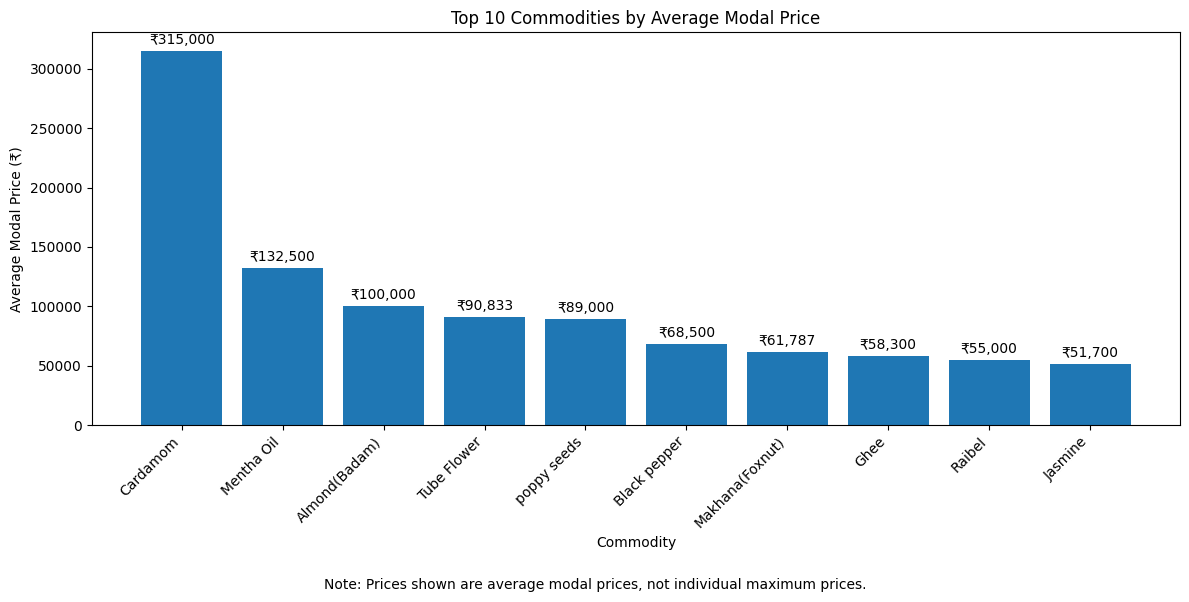

In [ ]:
# Top 10 Commodities by Average Modal Price

import matplotlib.pyplot as plt

# Calculate average Modal_Price for each commodity
avg_prices = df.groupby('Commodity')['Modal_Price'].mean()

# Select the top 10 commodities with the highest average prices
top_10_avg_prices = avg_prices.sort_values(ascending=False).head(10)

# Create the vertical bar chart
plt.figure(figsize=(12, 6))

bars = plt.bar(
    top_10_avg_prices.index,
    top_10_avg_prices.values
)

# Add chart title and axis labels
plt.title('Top 10 Commodities by Average Modal Price')
plt.xlabel('Commodity')
plt.ylabel('Average Modal Price (₹)')

# Rotate commodity names for readability
plt.xticks(rotation=45, ha='right')

# Add price labels with ₹ symbol and comma formatting
labels = [f'₹{value:,.0f}' for value in top_10_avg_prices.values]
plt.bar_label(bars, labels=labels, padding=3)

# Clarify that the chart shows average prices
plt.figtext(
    0.5, 0.01,
    'Note: Prices shown are average modal prices, not individual maximum prices.',
    ha='center',
    fontsize=10
)

# Adjust layout
plt.tight_layout(rect=[0, 0.05, 1, 1])

# Display the chart
plt.show()

The bar chart shows the average `Modal_Price` of the top 10 commodities. Cardamom has the highest average price at 315,000, followed by Mentha Oil and Almond(Badam). Jasmine has the lowest average among these 10 commodities at 51,700.

In [ ]:
#  Select relevant columns

state_price_data = df[['State', 'Modal_Price']].copy()

print(state_price_data.head())

print("\nData types:")
print(state_price_data.dtypes)

print("\nMissing values:")
print(state_price_data.isnull().sum())

     State  Modal_Price
1   Odisha       5500.0
2   Odisha       5000.0
3  Keralam       3600.0
4  Keralam       5000.0
5  Keralam       5200.0

Data types:
State          string[python]
Modal_Price           float64
dtype: object

Missing values:
State          0
Modal_Price    0
dtype: int64


Top 10 States: Average Modal Price and Record Count
                     Average_Modal_Price  Record_Count
State                                                 
Manipur                     10020.408163            49
Andaman and Nicobar          9133.391304            23
Karnataka                    7540.295495           555
Keralam                      6515.147690          1537
Jammu and Kashmir            6239.933628           226
Tripura                      6238.712871           101
Assam                        6190.069402           192
Tamil Nadu                   6101.788836         13750
NCT of Delhi                 5787.673267           101
Meghalaya                    5778.703704            54


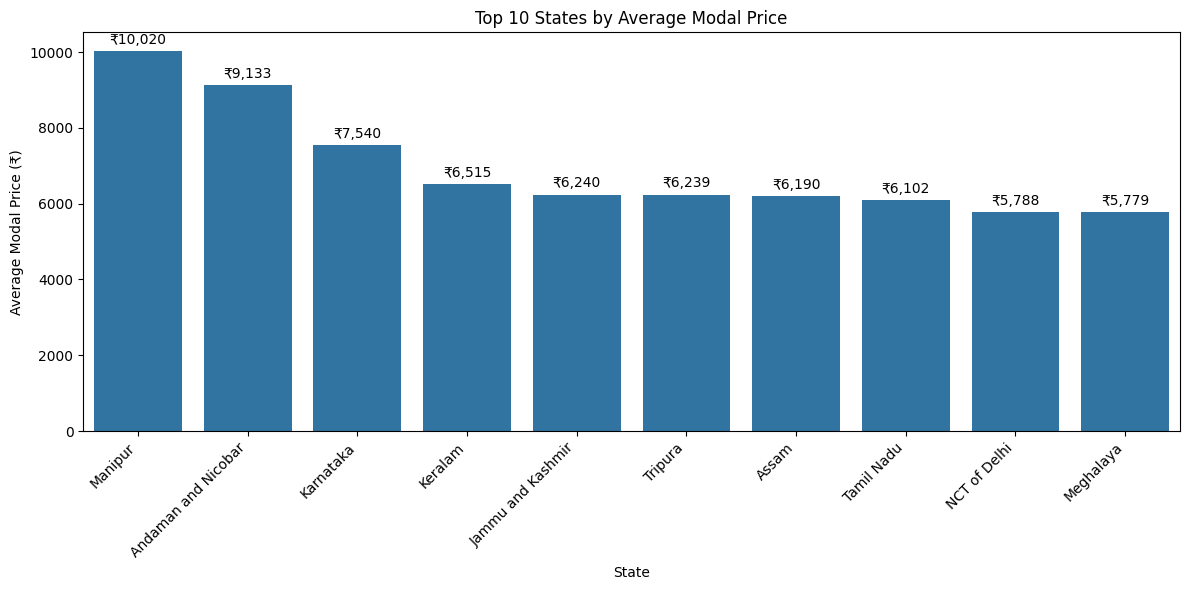

In [ ]:
# Top 10 States by Average Modal Price

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Calculate average modal price for each state
state_avg_prices = df.groupby('State')['Modal_Price'].mean()

# 2. Count the number of records for each state
state_record_counts = df.groupby('State')['Modal_Price'].count()

# 3. Select the top 10 states, sorted from highest to lowest average price
top_10_states = state_avg_prices.sort_values(ascending=False).head(10)

# 4. Display average prices and record counts
state_comparison = pd.DataFrame({
    'Average_Modal_Price': top_10_states,
    'Record_Count': state_record_counts.loc[top_10_states.index]
})

print("Top 10 States: Average Modal Price and Record Count")
print(state_comparison)

# 5. Create the bar chart
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_10_states.index,
    y=top_10_states.values,
    order=top_10_states.index
)

plt.title('Top 10 States by Average Modal Price')
plt.xlabel('State')
plt.ylabel('Average Modal Price (₹)')
plt.xticks(rotation=45, ha='right')

# 6. Add price labels with ₹ and comma formatting
labels = [f'₹{value:,.0f}' for value in top_10_states.values]
ax.bar_label(ax.containers[0], labels=labels, padding=3)

plt.tight_layout()
plt.show()

The chart shows that Manipur has the highest average modal price at approximately ₹10,020, followed by Andaman and Nicobar at ₹9,133, while Meghalaya has the lowest average among the top 10 locations at approximately ₹5,779. The number of records varies across locations, with 49 records for Manipur and 13,750 for Tamil Nadu, so record counts should be considered when comparing averages. These results show differences in average modal prices across locations but do not mean that every commodity is more expensive in Manipur.

In [ ]:
# Select the Modal_Price column

modal_price_data = df['Modal_Price'].copy()

print("First 5 Modal_Price values:")
print(modal_price_data.head())

print("\nData type:")
print(modal_price_data.dtype)

print("\nMissing values:")
print(modal_price_data.isnull().sum())

First 5 Modal_Price values:
1    5500.0
2    5000.0
3    3600.0
4    5000.0
5    5200.0
Name: Modal_Price, dtype: float64

Data type:
float64

Missing values:
0


In [ ]:
# Check the distribution of Modal_Price

print("Minimum Modal_Price:", modal_price_data.min())
print("Maximum Modal_Price:", modal_price_data.max())
print("Average Modal_Price:", round(modal_price_data.mean(), 2))
print("Median Modal_Price:", modal_price_data.median())

Minimum Modal_Price: 0.01
Maximum Modal_Price: 315000.0
Average Modal_Price: 5456.01
Median Modal_Price: 4000.0


Total records: 28268
Records included up to ₹20,000: 27659
Records excluded above ₹20,000: 609


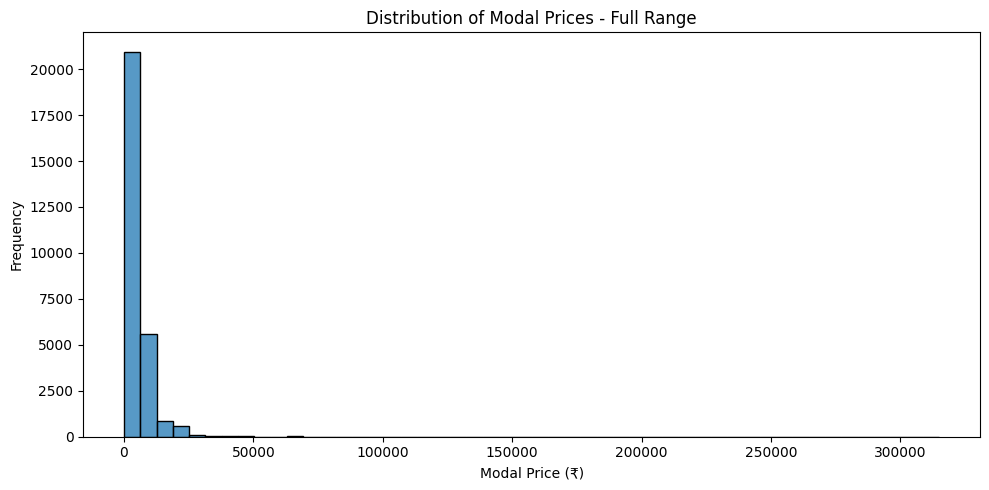

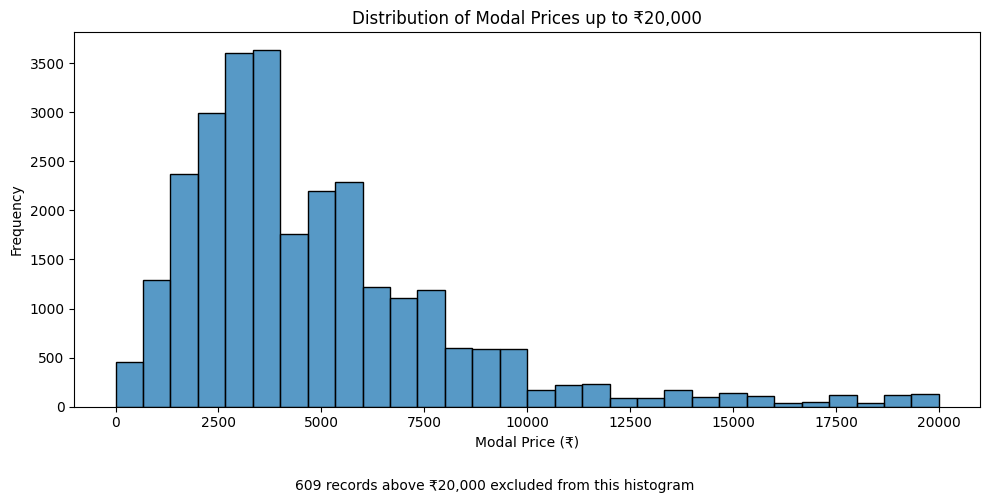

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Get modal prices and remove missing values
modal_prices = df['Modal_Price'].dropna()

# Count records included and excluded
included_records = (modal_prices <= 20000).sum()
excluded_records = (modal_prices > 20000).sum()

print("Total records:", len(modal_prices))
print("Records included up to ₹20,000:", included_records)
print("Records excluded above ₹20,000:", excluded_records)

# Histogram 1: Full price range
plt.figure(figsize=(10, 5))
sns.histplot(modal_prices, bins=50)

plt.title('Distribution of Modal Prices - Full Range')
plt.xlabel('Modal Price (₹)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


# Histogram 2: Prices up to ₹20,000
prices_up_to_20000 = modal_prices[modal_prices <= 20000]

plt.figure(figsize=(10, 5))
sns.histplot(prices_up_to_20000, bins=30)

plt.title('Distribution of Modal Prices up to ₹20,000')
plt.xlabel('Modal Price (₹)')
plt.ylabel('Frequency')

# Display excluded record count below the histogram
plt.figtext(
    0.5, 0.01,
    f'{excluded_records:,} records above ₹20,000 excluded from this histogram',
    ha='center',
    fontsize=10
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


The full-range histogram shows that most modal prices are concentrated at the lower end, while a small number of extremely high prices make the distribution difficult to interpret clearly. Therefore, a second histogram was created to display modal prices up to ₹20,000. Out of 28,268 records, 27,659 were included in the second histogram, while 609 records with modal prices above ₹20,000 were excluded from that histogram. These records were retained in the original dataset.

In [ ]:
#  Select the Modal_Price column

boxplot_data = df[['Modal_Price']].copy()

print("First 5 records:")
print(boxplot_data.head())

print("\nMissing values:")
print(boxplot_data.isnull().sum())

First 5 records:
   Modal_Price
1       5500.0
2       5000.0
3       3600.0
4       5000.0
5       5200.0

Missing values:
Modal_Price    0
dtype: int64


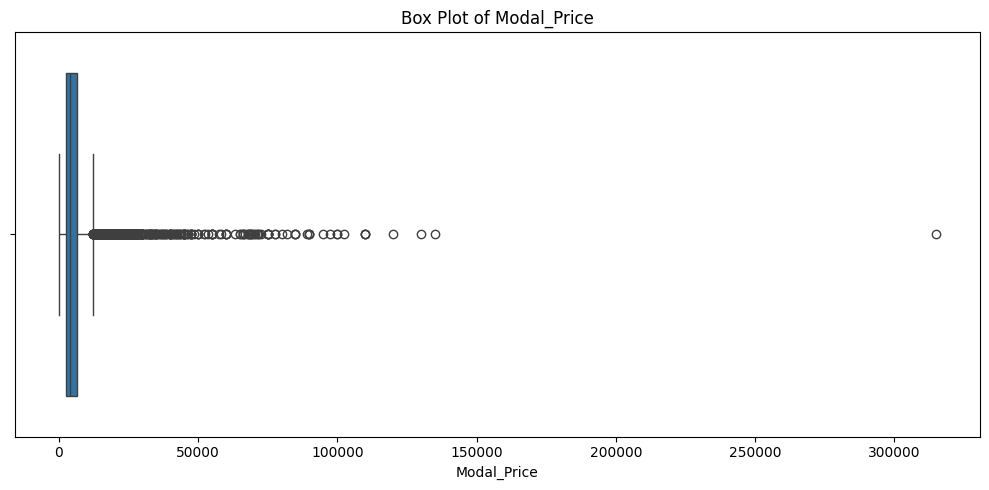

In [ ]:
#  Create a box plot using Seaborn

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(x=boxplot_data['Modal_Price'])

plt.title('Box Plot of Modal_Price')
plt.xlabel('Modal_Price')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate the first and third quartiles
Q1 = df['Modal_Price'].quantile(0.25)
Q3 = df['Modal_Price'].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Define the outlier limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Display the limits
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

# Display potential outliers
outliers = df[
    (df['Modal_Price'] < lower_limit) |
    (df['Modal_Price'] > upper_limit)
]

print("Number of potential outliers:", len(outliers))
display(outliers.head(10))

Q1: 2650.0
Q3: 6500.0
IQR: 3850.0
Lower limit: -3125.0
Upper limit: 12275.0
Number of potential outliers: 1782


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price
25,Keralam,Pathanamthitta,Kuttoor Market,Ginger(Green),Green Ginger,Local,2026-10-13,25100.0,25500.0,25300.0
29,Gujarat,Rajkot,JASDAN APMC,"Sesamum(Sesame,Gingelly,Til)",White,FAQ,2026-10-13,11000.0,16250.0,14500.0
31,Gujarat,Rajkot,JASDAN APMC,"Sesamum(Sesame,Gingelly,Til)",Black,FAQ,2026-10-13,10000.0,15000.0,13500.0
38,Keralam,Ernakulam,Thrippunithura Market,Lemon,Other,Medium,2026-10-13,19000.0,20000.0,19200.0
44,Gujarat,Surendranagar,Dhragradhra APMC,Cummin Seed(Jeera),Cummin Seed(Jeera),Local,2026-10-13,19525.0,24505.0,22000.0
97,Rajasthan,Kota,Kota APMC,Garlic,Other,Local,2026-10-13,13000.0,13000.0,13000.0
99,Rajasthan,Kota,Kota APMC,Corriander seed,Other,Local,2026-10-13,14000.0,14000.0,14000.0
104,Rajasthan,Jaipur,Jaipur (F&V) APMC,Pomegranate,Other,Medium,2026-10-13,5000.0,22000.0,13500.0
113,Rajasthan,Baran,Baran APMC,Corriander seed,Other,Local,2026-10-13,13210.0,16300.0,15100.0
137,Jammu and Kashmir,Kupwara,Bumhama Kupwara (F&V),Walnut,Other,Grade Range-1,2026-10-13,90000.0,100000.0,95000.0


#Box plot

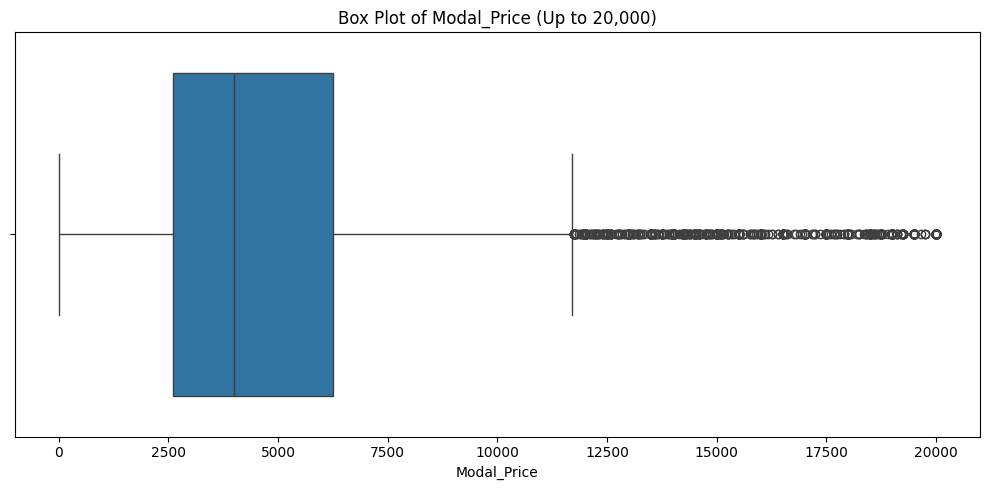

In [ ]:
# Box plot for Modal_Price up to 20,000

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=boxplot_data.loc[boxplot_data['Modal_Price'] <= 20000, 'Modal_Price']
)

plt.title('Box Plot of Modal_Price (Up to 20,000)')
plt.xlabel('Modal_Price')

plt.tight_layout()
plt.show()


The box plot shows that most modal prices are between ₹2,600 and ₹6,300, with a median of approximately ₹4,000. Several unusually high prices appear as outliers, extending up to ₹20,000. The distribution is right-skewed, indicating that a few commodities have much higher prices than most others. These outliers should be checked before correcting or removing any values.

#scatter chart

Total records checked: 28268
Records where Min_Price > Max_Price: 0
No records have Min_Price greater than Max_Price.


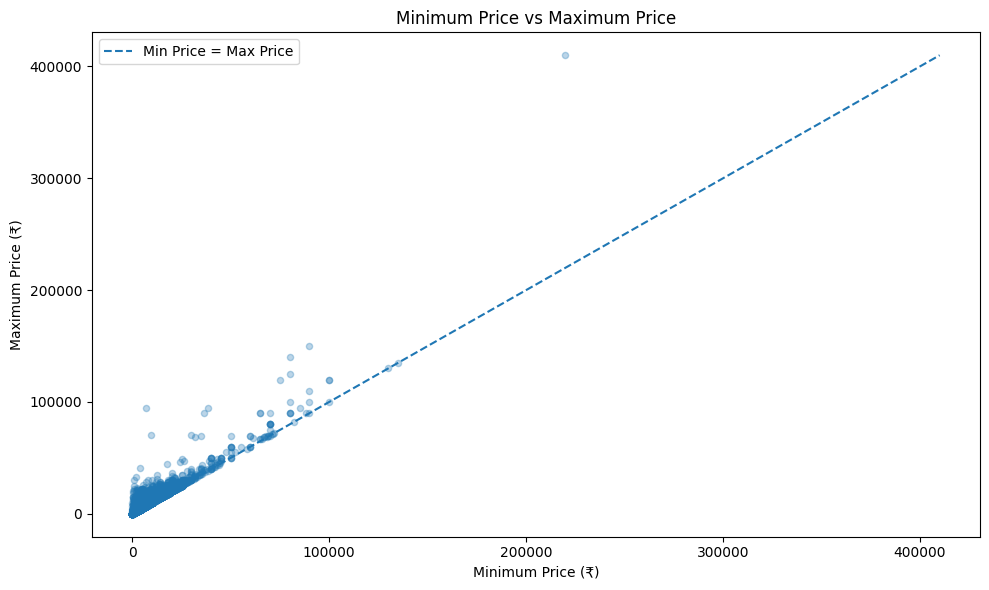

In [ ]:

import matplotlib.pyplot as plt

# Select price columns and remove missing values
price_data = df[['Min_Price', 'Max_Price']].dropna()

# Check for records where minimum price exceeds maximum price
incorrect_records = price_data[
    price_data['Min_Price'] > price_data['Max_Price']
]

print("Total records checked:", len(price_data))
print("Records where Min_Price > Max_Price:", len(incorrect_records))

if len(incorrect_records) > 0:
    print("\nRecords that need checking:")
    print(incorrect_records.head(10))
else:
    print("No records have Min_Price greater than Max_Price.")

# Create scatter plot with transparency
plt.figure(figsize=(10, 6))

plt.scatter(
    price_data['Min_Price'],
    price_data['Max_Price'],
    alpha=0.3,
    s=20
)

# Add reference line: Min_Price = Max_Price
max_value = max(
    price_data['Min_Price'].max(),
    price_data['Max_Price'].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle='--',
    label='Min Price = Max Price'
)

plt.title('Minimum Price vs Maximum Price')
plt.xlabel('Minimum Price (₹)')
plt.ylabel('Maximum Price (₹)')
plt.legend()
plt.tight_layout()
plt.show()


The scatter plot shows the relationship between minimum and maximum commodity prices. Transparency was added to make overlapping points easier to identify, and a dashed reference line was included to indicate where both prices are equal. Most records show maximum prices equal to or higher than minimum prices. The validation check found 0 records where the minimum price exceeded the maximum price among the 28,268 records checked. A few commodities have exceptionally high prices compared with the majority of records.

#Line chart

Average Modal Price Comparison Between Two Dates
13-10-2026: ₹5,464.88
16-10-2026: ₹5,445.03


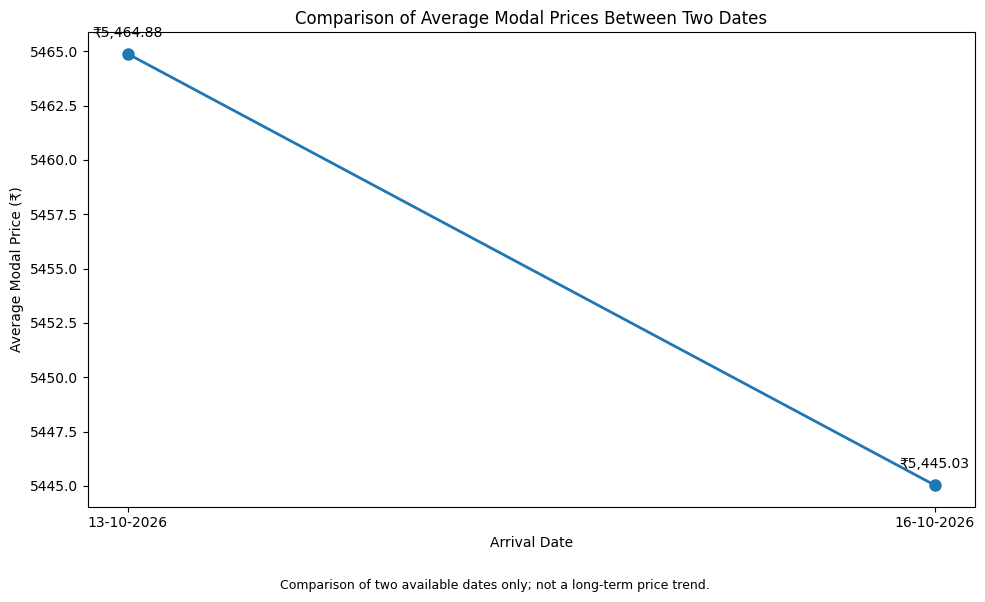

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert Arrival_Date to datetime
df['Arrival_Date'] = pd.to_datetime(
    df['Arrival_Date'],
    dayfirst=True,
    errors='coerce'
)

# Calculate average modal price for each date
date_avg_price = (
    df.groupby('Arrival_Date')['Modal_Price']
    .mean()
    .dropna()
    .sort_index()
)

# Display exact dates and average prices
print("Average Modal Price Comparison Between Two Dates")

for date, price in date_avg_price.items():
    print(f"{date.strftime('%d-%m-%Y')}: ₹{price:,.2f}")

# Create the line chart
fig, ax = plt.subplots(figsize=(10, 6))

dates = date_avg_price.index
prices = date_avg_price.values

ax.plot(
    dates,
    prices,
    marker='o',
    linewidth=2,
    markersize=8
)

# Display exact price values beside each point
for date, price in zip(dates, prices):
    ax.annotate(
        f'₹{price:,.2f}',
        (date, price),
        textcoords='offset points',
        xytext=(0, 12),
        ha='center'
    )

# Format the dates clearly
ax.set_xticks(dates)
ax.set_xticklabels(
    [date.strftime('%d-%m-%Y') for date in dates]
)

ax.set_title('Comparison of Average Modal Prices Between Two Dates')
ax.set_xlabel('Arrival Date')
ax.set_ylabel('Average Modal Price (₹)')

# Add a note clarifying the purpose of the chart
fig.text(
    0.5, 0.01,
    'Comparison of two available dates only; not a long-term price trend.',
    ha='center',
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()



The line chart compares the average modal prices of agricultural commodities on October 13, 2026, and October 16, 2026. The average modal price decreased from 5,465 on October 13 to 5,445 on October 16,  This indicates a slight decrease in the average modal price between the two observed dates.

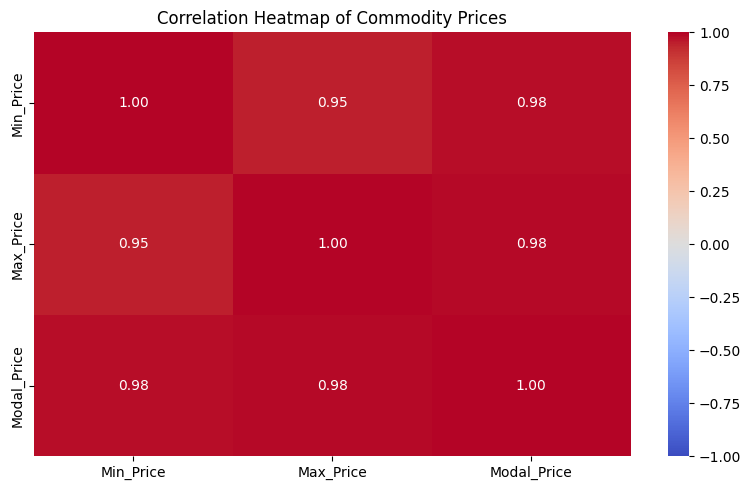

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical price columns
price_columns = df[['Min_Price', 'Max_Price', 'Modal_Price']]

# Calculate correlation
correlation = price_columns.corr()

# Create heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Commodity Prices')
plt.tight_layout()
plt.show()

The values are between 0.95 and 0.98, which means all three prices have a very strong relationship. When one price increases, the other prices generally increase too.

The value 1.00 on the diagonal means each price is perfectly related to itself.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select a commodity with records from multiple markets
commodity_counts = df.groupby('Commodity')['Market'].nunique()
eligible_commodities = commodity_counts[commodity_counts >= 2].index

print("Number of commodities available for comparison:", len(eligible_commodities))
print("\nSample commodities:")
print(sorted(eligible_commodities)[:20])

Number of commodities available for comparison: 197

Sample commodities:
['Ajwan', 'Alasande Gram', 'Amaranthus', 'Amla(Nelli Kai)', 'Amranthas Red', 'Apple', 'Arecanut(Betelnut/Supari)', 'Ashgourd', 'Baby Corn', 'Bajra(Pearl Millet/Cumbu)', 'Banana', 'Banana - Green', 'Barley(Jau)', 'Beans', 'Beetroot', 'Bengal Gram Dal(Chana Dal)', 'Bengal Gram(Gram)(Whole)', 'Betal Leaves', 'Bhindi(Ladies Finger)', 'Bitter gourd']


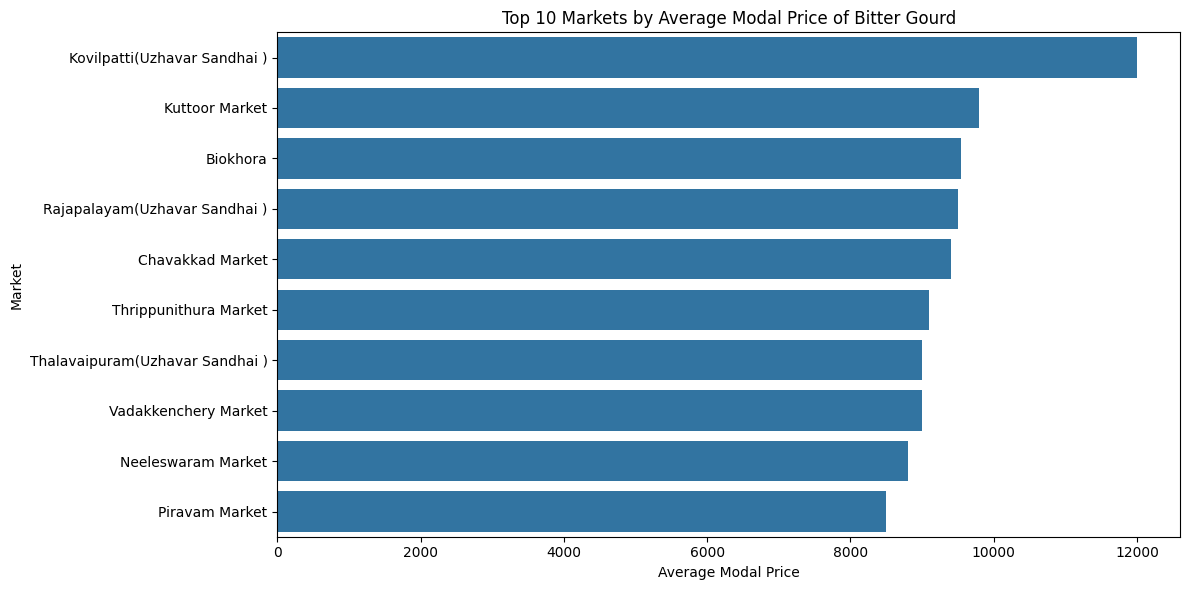

Market price comparison chart saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter the dataset for Bitter gourd
bitter_gourd = df[df['Commodity'] == 'Bitter gourd'].copy()

# Calculate average modal price for each market
market_prices = (
    bitter_gourd.groupby('Market')['Modal_Price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Create the bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=market_prices,
    x='Modal_Price',
    y='Market'
)

plt.title('Top 10 Markets by Average Modal Price of Bitter Gourd')
plt.xlabel('Average Modal Price')
plt.ylabel('Market')
plt.tight_layout()

# Save the chart
plt.savefig('bitter_gourd_market_price_comparison.png',
            dpi=300, bbox_inches='tight')

plt.show()

print("Market price comparison chart saved successfully!")

The bar chart compares the average modal price of bitter gourd across the top 10 markets. Kovilpatti (Uzhavar Sandhai) has the highest average price at approximately 12,000, while Piravam Market has the lowest at approximately 8,500 among the selected markets. The chart shows that bitter gourd prices vary across markets.

### Results and Findings

The analysis provided insights into agricultural commodity price variations across the available markets and states. The top 10 commodities were identified based on average modal prices, and state-wise average prices were compared. Price distributions and potential outliers were examined, while minimum and maximum prices were compared to understand price differences. The two reporting dates were also compared to observe changes in average modal prices.

### Conclusion

The Agriculture Market Price Records project demonstrates how Python can be used to clean, analyze, and visualize agricultural market data. The analysis helps identify differences in commodity prices across states and markets, examine price distributions, and understand potential outliers. The findings provide a useful overview of the agricultural market price records included in the dataset.